<a href="https://colab.research.google.com/github/KallebeTorres/KallebeTorres/blob/main/Compra_Clara_comentado_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Compra Clara — Pipeline completo v2
Preços públicos e indícios de anomalias
Esta versão substitui o notebook exploratório por um pipeline reproduzível e mais robusto:
- API oficial do Compras.gov.br (CATMAT + Pesquisa de Preços)
- paginação dinâmica
- retry e validação HTTP/JSON
- cache/checkpoints e log de erros
- Data Lake Bronze / Silver / Gold
- seleção mais precisa de hardware
- coleta automática de itens CATMAT e preços
- limpeza, padronização e deduplicação
- benchmark nacional/regional e por período
- detecção de outliers com IQR + MAD (robust z-score)
- estimativa de economia potencial
- classificação para revisão humana, sem afirmar fraude
- busca de item, relatórios CSV/XLSX e gráficos
- bloco opcional de PySpark para demonstração de Big Data
Fonte oficial: https://dadosabertos.compras.gov.br/swagger-ui/index.html

In [ ]:
# Instala as dependências externas necessárias para executar o projeto.
# 1) Dependências
# Em Colab, execute esta célula uma vez por ambiente.
!pip -q install requests pandas numpy matplotlib openpyxl pyarrow pyspark

In [ ]:
# 2) Imports e configuração central
# Importa recursos específicos de um módulo.
from __future__ import annotations

# Importa bibliotecas necessárias para esta etapa.
import os
# Importa bibliotecas necessárias para esta etapa.
import re
# Importa bibliotecas necessárias para esta etapa.
import json
# Importa bibliotecas necessárias para esta etapa.
import time
# Importa bibliotecas necessárias para esta etapa.
import math
# Importa bibliotecas necessárias para esta etapa.
import logging
# Importa bibliotecas necessárias para esta etapa.
import unicodedata
# Importa recursos específicos de um módulo.
from pathlib import Path
# Importa recursos específicos de um módulo.
from datetime import datetime, timezone
# Importa recursos específicos de um módulo.
from typing import Any, Dict, Iterable, List, Optional, Tuple

# Importa bibliotecas necessárias para esta etapa.
import numpy as np
# Importa bibliotecas necessárias para esta etapa.
import pandas as pd
# Importa bibliotecas necessárias para esta etapa.
import requests
# Importa bibliotecas necessárias para esta etapa.
import matplotlib.pyplot as plt

# Importa recursos específicos de um módulo.
from requests.adapters import HTTPAdapter
# Importa recursos específicos de um módulo.
from urllib3.util.retry import Retry

# ---------------- CONFIGURAÇÃO ----------------
# Armazena em `BASE_URL` o valor ou resultado calculado nesta etapa.
BASE_URL = "https://dadosabertos.compras.gov.br"
# Armazena em `URL_PDM` o valor ou resultado calculado nesta etapa.
URL_PDM = f"{BASE_URL}/modulo-material/3_consultarPdmMaterial"
# Armazena em `URL_ITEM` o valor ou resultado calculado nesta etapa.
URL_ITEM = f"{BASE_URL}/modulo-material/4_consultarItemMaterial"
# Armazena em `URL_PRECOS` o valor ou resultado calculado nesta etapa.
URL_PRECOS = f"{BASE_URL}/modulo-pesquisa-preco/1_consultarMaterial"

# Armazena em `TAMANHO_PAGINA` o valor ou resultado calculado nesta etapa.
TAMANHO_PAGINA = 500
# Armazena em `TIMEOUT` o valor ou resultado calculado nesta etapa.
TIMEOUT = 60
# Armazena em `PAUSA_ENTRE_REQUISICOES` o valor ou resultado calculado nesta etapa.
PAUSA_ENTRE_REQUISICOES = 0.15
# Armazena em `REUTILIZAR_CACHE` o valor ou resultado calculado nesta etapa.
REUTILIZAR_CACHE = True
# Armazena em `JANELA_DIAS` o valor ou resultado calculado nesta etapa.
JANELA_DIAS = 365
# Armazena em `MIN_AMOSTRA_BENCHMARK` o valor ou resultado calculado nesta etapa.
MIN_AMOSTRA_BENCHMARK = 5

# Para teste rápido, mude para um número (ex.: 20).
# None = processar todos os itens selecionados.
# Armazena em `MAX_ITENS_PRECOS` o valor ou resultado calculado nesta etapa.
MAX_ITENS_PRECOS = None

# Escopo desejado no MVP. A seleção usa nome exato normalizado + contexto de classe/grupo.
# Armazena em `ALVOS_PDM` o valor ou resultado calculado nesta etapa.
ALVOS_PDM = {
    "PROCESSADOR": "Processador",
    "MEMORIA RAM": "Memória RAM",
    "MODULO MEMORIA": "Módulo memória",
    "PENTE DE MEMORIA": "Pente de memória",
    "PLACA MAE": "Placa-mãe",
    "UNIDADE DE ESTADO SOLIDO": "SSD / unidade de estado sólido",
    "DISCO RIGIDO": "Disco rígido",
}

# Classes/grupos aceitáveis para reduzir falsos positivos.
# Armazena em `CLASSES_HARDWARE_ACEITAS` o valor ou resultado calculado nesta etapa.
CLASSES_HARDWARE_ACEITAS = {
    "PEÇAS E ACESSÓRIOS PARA COMPUTADORES",
    "COMPUTADORES",
    "EQUIPAMENTOS DE ARMAZENAMENTO DE DADOS",
    "MICROCIRCUITOS ELETRÔNICOS",
}
# Armazena em `GRUPOS_HARDWARE_ACEITOS` o valor ou resultado calculado nesta etapa.
GRUPOS_HARDWARE_ACEITOS = {59, 70}

# Executa `logging.basicConfig` para realizar a operação indicada.
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    datefmt="%H:%M:%S",
)
# Armazena em `logger` o valor ou resultado calculado nesta etapa.
logger = logging.getLogger("CompraClara")

# Executa `print` para realizar a operação indicada.
print("Configuração carregada.")

Configuração carregada.


In [ ]:
# 3) Google Drive e estrutura do Data Lake
# Executa o trecho protegido e permite tratar possíveis exceções.
try:
    # Importa recursos específicos de um módulo.
    from google.colab import drive
    # Executa `drive.mount` para realizar a operação indicada.
    drive.mount('/content/drive')
    # Armazena em `BASE` o valor ou resultado calculado nesta etapa.
    BASE = Path('/content/drive/MyDrive/Compra_Clara')
except Exception:
    # Permite executar fora do Colab sem quebrar o notebook.
    # Armazena em `BASE` o valor ou resultado calculado nesta etapa.
    BASE = Path.cwd() / 'Compra_Clara'

# Armazena em `BRONZE` o valor ou resultado calculado nesta etapa.
BRONZE = BASE / 'dados' / 'bronze'
# Armazena em `SILVER` o valor ou resultado calculado nesta etapa.
SILVER = BASE / 'dados' / 'silver'
# Armazena em `GOLD` o valor ou resultado calculado nesta etapa.
GOLD = BASE / 'dados' / 'gold'
# Armazena em `RELATORIOS` o valor ou resultado calculado nesta etapa.
RELATORIOS = BASE / 'relatorios'
# Armazena em `LOGS` o valor ou resultado calculado nesta etapa.
LOGS = BASE / 'logs'

# Percorre os elementos da coleção, executando o bloco para cada um.
for pasta in [BRONZE, SILVER, GOLD, RELATORIOS, LOGS]:
    # Executa `pasta.mkdir` para realizar a operação indicada.
    pasta.mkdir(parents=True, exist_ok=True)

# Armazena em `RUN_ID` o valor ou resultado calculado nesta etapa.
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
# Executa `print` para realizar a operação indicada.
print('Base do projeto:', BASE)
# Executa `print` para realizar a operação indicada.
print('RUN_ID:', RUN_ID)

Mounted at /content/drive
Base do projeto: /content/drive/MyDrive/Compra_Clara
RUN_ID: 20261125T111016Z


In [ ]:
# 4) Funções utilitárias: normalização, sessão HTTP, JSON e persistência

# Define a função `normalizar_texto`, responsável por normalizar texto.
def normalizar_texto(valor: Any) -> str:
    # Verifica a condição antes de executar o bloco abaixo.
    if pd.isna(valor):
        # Devolve o resultado calculado pela função.
        return ""
    # Armazena em `texto` o valor ou resultado calculado nesta etapa.
    texto = str(valor).strip().upper()
    # Armazena em `texto` o valor ou resultado calculado nesta etapa.
    texto = unicodedata.normalize('NFKD', texto)
    # Armazena em `texto` o valor ou resultado calculado nesta etapa.
    texto = ''.join(c for c in texto if not unicodedata.combining(c))
    # Armazena em `texto` o valor ou resultado calculado nesta etapa.
    texto = re.sub(r'\s+', ' ', texto)
    # Devolve o resultado calculado pela função.
    return texto


# Define a função `criar_sessao`, responsável por criar sessao.
def criar_sessao() -> requests.Session:
    # Armazena em `sessao` o valor ou resultado calculado nesta etapa.
    sessao = requests.Session()
    # Armazena em `retry` o valor ou resultado calculado nesta etapa.
    retry = Retry(
        total=4,
        connect=4,
        read=4,
        status=4,
        backoff_factor=0.8,
        status_forcelist=(429, 500, 502, 503, 504),
        allowed_methods=frozenset(['GET']),
        raise_on_status=False,
    )
    # Armazena em `adapter` o valor ou resultado calculado nesta etapa.
    adapter = HTTPAdapter(max_retries=retry, pool_connections=10, pool_maxsize=10)
    # Executa `sessao.mount` para realizar a operação indicada.
    sessao.mount('https://', adapter)
    # Executa `sessao.mount` para realizar a operação indicada.
    sessao.mount('http://', adapter)
    # Executa `sessao.headers.update` para realizar a operação indicada.
    sessao.headers.update({'User-Agent': 'Compra-Clara/2.0'})
    # Devolve o resultado calculado pela função.
    return sessao

# Armazena em `SESSION` o valor ou resultado calculado nesta etapa.
SESSION = criar_sessao()


# Define a função `requisitar_json`, responsável por requisitar json.
def requisitar_json(url: str, params: Dict[str, Any], timeout: int = TIMEOUT) -> Dict[str, Any]:
    # Executa esta instrução como parte do processamento.
    """GET robusto: valida HTTP, JSON e estrutura mínima da resposta."""
    # Armazena em `resposta` o valor ou resultado calculado nesta etapa.
    resposta = SESSION.get(url, params=params, timeout=timeout)
    # Executa `resposta.raise_for_status` para realizar a operação indicada.
    resposta.raise_for_status()
    # Executa o trecho protegido e permite tratar possíveis exceções.
    try:
        # Armazena em `dados` o valor ou resultado calculado nesta etapa.
        dados = resposta.json()
    except ValueError as exc:
        # Armazena em `trecho` o valor ou resultado calculado nesta etapa.
        trecho = resposta.text[:500]
        # Interrompe a execução sinalizando uma condição de erro.
        raise RuntimeError(f'Resposta não-JSON recebida de {url}: {trecho}') from exc

    # Verifica a condição antes de executar o bloco abaixo.
    if not isinstance(dados, dict):
        # Interrompe a execução sinalizando uma condição de erro.
        raise RuntimeError(f'Resposta inesperada de {url}: esperado dict, recebido {type(dados).__name__}')
    # Devolve o resultado calculado pela função.
    return dados


# Define a função `salvar_json`, responsável por salvar json.
def salvar_json(obj: Any, caminho: Path) -> None:
    # Executa `caminho.parent.mkdir` para realizar a operação indicada.
    caminho.parent.mkdir(parents=True, exist_ok=True)
    # Abre um contexto de execução e garante seu encerramento adequado.
    with caminho.open('w', encoding='utf-8') as arq:
        # Executa `json.dump` para realizar a operação indicada.
        json.dump(obj, arq, ensure_ascii=False, indent=2, default=str)


# Define a função `carregar_json`, responsável por carregar json.
def carregar_json(caminho: Path) -> Any:
    # Abre um contexto de execução e garante seu encerramento adequado.
    with caminho.open('r', encoding='utf-8') as arq:
        # Devolve o resultado calculado pela função.
        return json.load(arq)


# Define a função `salvar_dataframe`, responsável por salvar dataframe.
def salvar_dataframe(df: pd.DataFrame, pasta: Path, nome: str) -> Tuple[Path, Path]:
    # Executa `pasta.mkdir` para realizar a operação indicada.
    pasta.mkdir(parents=True, exist_ok=True)

    # Armazena em `csv_path` o valor ou resultado calculado nesta etapa.
    csv_path = pasta / f'{nome}.csv'
    # Armazena em `parquet_path` o valor ou resultado calculado nesta etapa.
    parquet_path = pasta / f'{nome}.parquet'

    # Executa `df.to_csv` para realizar a operação indicada.
    df.to_csv(csv_path, index=False, encoding='utf-8-sig')

    # Executa `df.to_parquet` para realizar a operação indicada.
    df.to_parquet(
        parquet_path,
        index=False,
        engine='pyarrow',
        coerce_timestamps='us',
        allow_truncated_timestamps=True
    )

    # Devolve o resultado calculado pela função.
    return csv_path, parquet_path

# Executa `print` para realizar a operação indicada.
print('Utilitários preparados.')

Utilitários preparados.


In [ ]:
# 5) Coletor genérico com paginação dinâmica

# Define a função `coletar_todas_paginas`, responsável por coletar todas paginas.
def coletar_todas_paginas(
    url: str,
    params_base: Optional[Dict[str, Any]] = None,
    tamanho_pagina: int = TAMANHO_PAGINA,
    pausa: float = PAUSA_ENTRE_REQUISICOES,
) -> Dict[str, Any]:
    # Armazena em `params_base` o valor ou resultado calculado nesta etapa.
    params_base = dict(params_base or {})

    # Armazena em `primeira_params` o valor ou resultado calculado nesta etapa.
    primeira_params = {**params_base, 'pagina': 1, 'tamanhoPagina': tamanho_pagina}
    # Armazena em `primeira` o valor ou resultado calculado nesta etapa.
    primeira = requisitar_json(url, primeira_params)

    # Armazena em `paginas_raw` o valor ou resultado calculado nesta etapa.
    paginas_raw = [primeira]
    # Armazena em `registros` o valor ou resultado calculado nesta etapa.
    registros = list(primeira.get('resultado') or [])
    # Armazena em `total_paginas` o valor ou resultado calculado nesta etapa.
    total_paginas = int(primeira.get('totalPaginas') or (1 if registros else 0))
    # Armazena em `total_registros_api` o valor ou resultado calculado nesta etapa.
    total_registros_api = int(primeira.get('totalRegistros') or len(registros))

    # Percorre os elementos da coleção, executando o bloco para cada um.
    for pagina in range(2, total_paginas + 1):
        # Armazena em `params` o valor ou resultado calculado nesta etapa.
        params = {**params_base, 'pagina': pagina, 'tamanhoPagina': tamanho_pagina}
        # Armazena em `dados` o valor ou resultado calculado nesta etapa.
        dados = requisitar_json(url, params)
        # Executa `paginas_raw.append` para realizar a operação indicada.
        paginas_raw.append(dados)
        # Executa `registros.extend` para realizar a operação indicada.
        registros.extend(dados.get('resultado') or [])
        # Executa `logger.info` para realizar a operação indicada.
        logger.info('Página %s/%s | %s registros acumulados', pagina, total_paginas, len(registros))
        # Verifica a condição antes de executar o bloco abaixo.
        if pausa:
            # Executa `time.sleep` para realizar a operação indicada.
            time.sleep(pausa)

    # Nunca declarar sucesso silencioso se a quantidade divergir da metadata da API.
    # Verifica a condição antes de executar o bloco abaixo.
    if total_registros_api != len(registros):
        # Executa `logger.warning` para realizar a operação indicada.
        logger.warning(
            'Divergência de contagem: API informa %s, coleta obteve %s.',
            total_registros_api, len(registros)
        )

    # Devolve o resultado calculado pela função.
    return {
        'metadata_coleta': {
            'coletado_em_utc': datetime.now(timezone.utc).isoformat(),
            'url': url,
            'params_base': params_base,
            'tamanho_pagina': tamanho_pagina,
            'total_paginas': total_paginas,
            'total_registros_api': total_registros_api,
            'total_registros_coletados': len(registros),
        },
        'paginas_raw': paginas_raw,
        'resultado': registros,
    }

# Executa `print` para realizar a operação indicada.
print('Coletor paginado preparado.')

Coletor paginado preparado.


Etapa A — Catálogo PDM (Bronze → seleção de hardware)
A seleção deixa de procurar palavras genéricas no catálogo inteiro. Primeiro restringimos o contexto de grupo/classe e depois usamos nomes normalizados exatos para reduzir falsos positivos como “processador de alimentos” ou “placa principal relógio ponto”.

In [ ]:
# 6) Coleta completa de PDMs + Bronze
# Armazena em `arquivo_pdms` o valor ou resultado calculado nesta etapa.
arquivo_pdms = BRONZE / f'pdms_{RUN_ID}.json'

# Verifica a condição antes de executar o bloco abaixo.
if REUTILIZAR_CACHE:
    # Armazena em `caches` o valor ou resultado calculado nesta etapa.
    caches = sorted(BRONZE.glob('pdms_*.json'))
else:
    # Armazena em `caches` o valor ou resultado calculado nesta etapa.
    caches = []

# Verifica a condição antes de executar o bloco abaixo.
if caches:
    # Armazena em `bundle_pdms` o valor ou resultado calculado nesta etapa.
    bundle_pdms = carregar_json(caches[-1])
    # Executa `logger.info` para realizar a operação indicada.
    logger.info('PDMs carregados do cache: %s', caches[-1].name)
else:
    # Armazena em `bundle_pdms` o valor ou resultado calculado nesta etapa.
    bundle_pdms = coletar_todas_paginas(URL_PDM)
    # Executa `salvar_json` para realizar a operação indicada.
    salvar_json(bundle_pdms, arquivo_pdms)
    # Executa `logger.info` para realizar a operação indicada.
    logger.info('PDMs salvos na Bronze: %s', arquivo_pdms)

# Armazena em `pdms` o valor ou resultado calculado nesta etapa.
pdms = pd.DataFrame(bundle_pdms.get('resultado', []))
# Verifica a condição antes de executar o bloco abaixo.
if pdms.empty:
    # Interrompe a execução sinalizando uma condição de erro.
    raise RuntimeError('A API não retornou PDMs.')

# Executa `print` para realizar a operação indicada.
print('PDMs coletados:', len(pdms))
# Executa `display` para realizar a operação indicada.
display(pdms.head())

PDMs coletados: 20445


,codigoGrupo,nomeGrupo,codigoClasse,nomeClasse,codigoPdm,nomePdm,statusPdm,dataHoraAtualizacao
0,10,ARMAMENTO,1005,ARMAS DE FOGO DE CALIBRE ATÉ 120MM,2995,ARMA DE FOGO DE PEQUENO PORTE - REVÓLVER / PIS...,True,2021-10-16T09:21:41.961529
1,10,ARMAMENTO,1005,ARMAS DE FOGO DE CALIBRE ATÉ 120MM,4050,CABO PARA ARMA DE FOGO,True,2021-10-16T09:21:41.961529
2,10,ARMAMENTO,1005,ARMAS DE FOGO DE CALIBRE ATÉ 120MM,7889,FUZIS,True,2021-10-16T09:21:41.961529
3,10,ARMAMENTO,1005,ARMAS DE FOGO DE CALIBRE ATÉ 120MM,10799,PISTOLA,True,2021-10-16T09:21:41.961529
4,10,ARMAMENTO,1005,ARMAS DE FOGO DE CALIBRE ATÉ 120MM,13794,ANEL FERROLHO,True,2021-10-16T09:21:41.961529


In [ ]:
# 7) Seleção precisa dos PDMs de hardware
# Armazena em `pdms_sel` o valor ou resultado calculado nesta etapa.
pdms_sel = pdms.copy()
# Armazena em `pdms_sel['nomePdm_norm']` o valor ou resultado calculado nesta etapa.
pdms_sel['nomePdm_norm'] = pdms_sel['nomePdm'].map(normalizar_texto)
# Armazena em `pdms_sel['nomeClasse_norm']` o valor ou resultado calculado nesta etapa.
pdms_sel['nomeClasse_norm'] = pdms_sel['nomeClasse'].map(normalizar_texto)

# Armazena em `classes_norm` o valor ou resultado calculado nesta etapa.
classes_norm = {normalizar_texto(x) for x in CLASSES_HARDWARE_ACEITAS}

# Armazena em `mascara_contexto` o valor ou resultado calculado nesta etapa.
mascara_contexto = (
    pdms_sel['codigoGrupo'].isin(GRUPOS_HARDWARE_ACEITOS)
    | pdms_sel['nomeClasse_norm'].isin(classes_norm)
)

# Armazena em `mascara_nome` o valor ou resultado calculado nesta etapa.
mascara_nome = pdms_sel['nomePdm_norm'].isin(ALVOS_PDM.keys())
# Armazena em `mascara_ativo` o valor ou resultado calculado nesta etapa.
mascara_ativo = pdms_sel['statusPdm'].fillna(False).astype(bool)

# Armazena em `hardware_pdms` o valor ou resultado calculado nesta etapa.
hardware_pdms = pdms_sel[mascara_contexto & mascara_nome & mascara_ativo].copy()
# Armazena em `hardware_pdms['componente']` o valor ou resultado calculado nesta etapa.
hardware_pdms['componente'] = hardware_pdms['nomePdm_norm'].map(ALVOS_PDM)
# Armazena em `hardware_pdms` o valor ou resultado calculado nesta etapa.
hardware_pdms = hardware_pdms.drop_duplicates(subset=['codigoPdm'])

# Armazena em `faltantes` o valor ou resultado calculado nesta etapa.
faltantes = sorted(set(ALVOS_PDM) - set(hardware_pdms['nomePdm_norm']))
# Verifica a condição antes de executar o bloco abaixo.
if faltantes:
    # Executa `logger.warning` para realizar a operação indicada.
    logger.warning('PDMs-alvo não encontrados/ativos: %s', faltantes)

# Armazena em `colunas_exibir` o valor ou resultado calculado nesta etapa.
colunas_exibir = ['componente','codigoGrupo','nomeClasse','codigoClasse','codigoPdm','nomePdm','statusPdm']
# Executa `display` para realizar a operação indicada.
display(hardware_pdms[colunas_exibir].sort_values('componente').reset_index(drop=True))
# Executa `print` para realizar a operação indicada.
print('PDMs válidos selecionados:', len(hardware_pdms))

,componente,codigoGrupo,nomeClasse,codigoClasse,codigoPdm,nomePdm,statusPdm
0,Memória RAM,70,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,7060,9597,MEMÓRIA RAM,True
1,Módulo memória,70,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,7060,15899,MÓDULO MEMÓRIA,True
2,Pente de memória,70,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,7060,14256,PENTE DE MEMÓRIA,True
3,Placa-mãe,70,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,7060,14148,PLACA MÃE,True
4,Processador,70,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,7060,14431,PROCESSADOR,True


PDMs válidos selecionados: 5


Etapa B — Itens CATMAT (Bronze → Silver)
Cada PDM selecionado é consultado com paginação automática. Os itens brutos são preservados na Bronze e a Silver contém apenas itens ativos e códigos únicos.

In [ ]:
# 8) Coleta de todos os itens CATMAT dos PDMs selecionados
# Armazena em `itens_todos` o valor ou resultado calculado nesta etapa.
itens_todos = []
# Armazena em `erros_itens` o valor ou resultado calculado nesta etapa.
erros_itens = []

# Percorre os elementos da coleção, executando o bloco para cada um.
for _, linha in hardware_pdms.iterrows():
    # Armazena em `componente` o valor ou resultado calculado nesta etapa.
    componente = linha['componente']
    # Armazena em `codigo_pdm` o valor ou resultado calculado nesta etapa.
    codigo_pdm = int(linha['codigoPdm'])
    # Armazena em `cache` o valor ou resultado calculado nesta etapa.
    cache = BRONZE / 'itens' / f'pdm_{codigo_pdm}.json'

    # Executa o trecho protegido e permite tratar possíveis exceções.
    try:
        # Verifica a condição antes de executar o bloco abaixo.
        if REUTILIZAR_CACHE and cache.exists():
            # Armazena em `bundle` o valor ou resultado calculado nesta etapa.
            bundle = carregar_json(cache)
        else:
            # Armazena em `bundle` o valor ou resultado calculado nesta etapa.
            bundle = coletar_todas_paginas(URL_ITEM, {'codigoPdm': codigo_pdm})
            # Executa `salvar_json` para realizar a operação indicada.
            salvar_json(bundle, cache)

        # Armazena em `registros` o valor ou resultado calculado nesta etapa.
        registros = bundle.get('resultado', [])
        # Percorre os elementos da coleção, executando o bloco para cada um.
        for item in registros:
            # Armazena em `item` o valor ou resultado calculado nesta etapa.
            item = dict(item)
            # Armazena em `item['componente_pesquisado']` o valor ou resultado calculado nesta etapa.
            item['componente_pesquisado'] = componente
            # Executa `itens_todos.append` para realizar a operação indicada.
            itens_todos.append(item)
        # Executa `logger.info` para realizar a operação indicada.
        logger.info('%s | PDM %s | %s itens', componente, codigo_pdm, len(registros))

    except Exception as exc:
        # Executa `logger.exception` para realizar a operação indicada.
        logger.exception('Falha no PDM %s', codigo_pdm)
        # Executa `erros_itens.append` para realizar a operação indicada.
        erros_itens.append({'etapa':'itens', 'codigoPdm':codigo_pdm, 'componente':componente, 'erro':str(exc)})

# Armazena em `itens_raw` o valor ou resultado calculado nesta etapa.
itens_raw = pd.DataFrame(itens_todos)
# Verifica a condição antes de executar o bloco abaixo.
if itens_raw.empty:
    # Interrompe a execução sinalizando uma condição de erro.
    raise RuntimeError('Nenhum item CATMAT foi coletado.')

# Verifica a condição antes de executar o bloco abaixo.
if erros_itens:
    # Executa `pd.DataFrame(erros_itens).to_csv` para realizar a operação indicada.
    pd.DataFrame(erros_itens).to_csv(LOGS / f'erros_itens_{RUN_ID}.csv', index=False)

# Executa `print` para realizar a operação indicada.
print('Itens CATMAT brutos:', len(itens_raw))
# Executa `display` para realizar a operação indicada.
display(itens_raw.head())

Itens CATMAT brutos: 667


,codigoItem,codigoGrupo,nomeGrupo,codigoClasse,nomeClasse,codigoPdm,nomePdm,descricaoItem,statusItem,itemSustentavel,codigo_ncm,descricao_ncm,aplica_margem_preferencia,dataHoraAtualizacao,componente_pesquisado
0,249464,70,"INFORMÁTICA - EQUIPAMENTOS, PEÇAS, ACESSÓRIOS...",7060,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,14148,PLACA MÃE,"PLACA MÃE, COMPONENTES: SOCKET 478 / SLOT AGP_...",True,False,None,None,None,2021-10-16T09:43:08.030221,Placa-mãe
1,239130,70,"INFORMÁTICA - EQUIPAMENTOS, PEÇAS, ACESSÓRIOS...",7060,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,14148,PLACA MÃE,"PLACA MÃE, COMPONENTES: 4 SLOTS, 5 PCI , APLIC...",True,False,None,None,None,2021-10-16T09:43:08.030221,Placa-mãe
2,304783,70,"INFORMÁTICA - EQUIPAMENTOS, PEÇAS, ACESSÓRIOS...",7060,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,14148,PLACA MÃE,"PLACA MÃE, COMPONENTES: SLOT AGP / SLOT PCI / ...",True,False,None,None,None,2021-10-16T09:43:08.030221,Placa-mãe
3,258905,70,"INFORMÁTICA - EQUIPAMENTOS, PEÇAS, ACESSÓRIOS...",7060,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,14148,PLACA MÃE,"PLACA MÃE, COMPONENTES: SLOT AGP/SLOT PCI/SLOT...",True,False,None,None,None,2021-10-16T09:43:08.030221,Placa-mãe
4,297969,70,"INFORMÁTICA - EQUIPAMENTOS, PEÇAS, ACESSÓRIOS...",7060,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,14148,PLACA MÃE,"PLACA MÃE, COMPONENTES: SOCKET 939, 5 SLOTS PC...",True,False,None,None,None,2021-10-16T09:43:08.030221,Placa-mãe


In [ ]:
# 9) Silver de itens: ativos, únicos e com schema mínimo
# Armazena em `itens` o valor ou resultado calculado nesta etapa.
itens = itens_raw.copy()

# Verifica a condição antes de executar o bloco abaixo.
if 'statusItem' in itens:
    # Armazena em `itens` o valor ou resultado calculado nesta etapa.
    itens = itens[itens['statusItem'].fillna(False).astype(bool)]

# Armazena em `itens['codigoItem']` o valor ou resultado calculado nesta etapa.
itens['codigoItem'] = pd.to_numeric(itens['codigoItem'], errors='coerce').astype('Int64')
# Armazena em `itens` o valor ou resultado calculado nesta etapa.
itens = itens.dropna(subset=['codigoItem'])
# Armazena em `itens` o valor ou resultado calculado nesta etapa.
itens = itens.drop_duplicates(subset=['codigoItem']).reset_index(drop=True)

# Armazena em `colunas_itens` o valor ou resultado calculado nesta etapa.
colunas_itens = [c for c in [
    'componente_pesquisado','codigoPdm','codigoItem','descricaoItem','statusItem'
] if c in itens.columns]
# Armazena em `itens_silver` o valor ou resultado calculado nesta etapa.
itens_silver = itens[colunas_itens].copy()

# Executa `salvar_dataframe` para realizar a operação indicada.
salvar_dataframe(itens_silver, SILVER, 'itens_hardware_latest')
# Executa `print` para realizar a operação indicada.
print('Itens ativos e únicos na Silver:', len(itens_silver))
# Executa `display` para realizar a operação indicada.
display(itens_silver.groupby('componente_pesquisado')['codigoItem'].nunique().sort_values(ascending=False).to_frame('itens_unicos'))

Itens ativos e únicos na Silver: 658


,itens_unicos
componente_pesquisado,
Pente de memória,280
Processador,185
Placa-mãe,134
Módulo memória,30
Memória RAM,29


Etapa C — Pesquisa de preços (Bronze com checkpoint)
A coleta percorre automaticamente os CATMATs. Cada código é salvo separadamente na Bronze, permitindo retomar a execução sem repetir chamadas que já foram concluídas.

In [ ]:
# 10) Coleta paginada de preços para todos os itens selecionados
# Armazena em `codigos` o valor ou resultado calculado nesta etapa.
codigos = itens_silver['codigoItem'].dropna().astype(int).tolist()
# Verifica a condição antes de executar o bloco abaixo.
if MAX_ITENS_PRECOS is not None:
    # Armazena em `codigos` o valor ou resultado calculado nesta etapa.
    codigos = codigos[:MAX_ITENS_PRECOS]

# Armazena em `precos_todos` o valor ou resultado calculado nesta etapa.
precos_todos = []
# Armazena em `erros_precos` o valor ou resultado calculado nesta etapa.
erros_precos = []

# Percorre os elementos da coleção, executando o bloco para cada um.
for pos, codigo in enumerate(codigos, start=1):
    # Armazena em `cache` o valor ou resultado calculado nesta etapa.
    cache = BRONZE / 'precos' / f'catmat_{codigo}.json'
    # Executa o trecho protegido e permite tratar possíveis exceções.
    try:
        # Verifica a condição antes de executar o bloco abaixo.
        if REUTILIZAR_CACHE and cache.exists():
            # Armazena em `bundle` o valor ou resultado calculado nesta etapa.
            bundle = carregar_json(cache)
        else:
            # Armazena em `bundle` o valor ou resultado calculado nesta etapa.
            bundle = coletar_todas_paginas(
                URL_PRECOS,
                {'tipo': 'codigoItemCatalogo', 'codigo': codigo},
                tamanho_pagina=TAMANHO_PAGINA,
            )
            # Executa `salvar_json` para realizar a operação indicada.
            salvar_json(bundle, cache)

        # Armazena em `registros` o valor ou resultado calculado nesta etapa.
        registros = bundle.get('resultado', [])
        # Percorre os elementos da coleção, executando o bloco para cada um.
        for registro in registros:
            # Armazena em `registro` o valor ou resultado calculado nesta etapa.
            registro = dict(registro)
            # Armazena em `registro['_codigo_consultado']` o valor ou resultado calculado nesta etapa.
            registro['_codigo_consultado'] = codigo
            # Executa `precos_todos.append` para realizar a operação indicada.
            precos_todos.append(registro)

        # Verifica a condição antes de executar o bloco abaixo.
        if pos % 20 == 0 or pos == len(codigos):
            # Executa `logger.info` para realizar a operação indicada.
            logger.info('Preços: %s/%s CATMATs processados | %s registros', pos, len(codigos), len(precos_todos))

    except Exception as exc:
        # Executa `logger.exception` para realizar a operação indicada.
        logger.exception('Falha na coleta de preços do CATMAT %s', codigo)
        # Executa `erros_precos.append` para realizar a operação indicada.
        erros_precos.append({'etapa':'precos','codigoItem':codigo,'erro':str(exc)})

# Armazena em `precos_raw` o valor ou resultado calculado nesta etapa.
precos_raw = pd.DataFrame(precos_todos)
# Verifica a condição antes de executar o bloco abaixo.
if erros_precos:
    # Executa `pd.DataFrame(erros_precos).to_csv` para realizar a operação indicada.
    pd.DataFrame(erros_precos).to_csv(LOGS / f'erros_precos_{RUN_ID}.csv', index=False)

# Armazena em `total_planejado` o valor ou resultado calculado nesta etapa.
total_planejado = len(codigos)
# Armazena em `total_erros` o valor ou resultado calculado nesta etapa.
total_erros = len(erros_precos)
# Armazena em `total_sucesso` o valor ou resultado calculado nesta etapa.
total_sucesso = total_planejado - total_erros

# Armazena em `taxa_sucesso` o valor ou resultado calculado nesta etapa.
taxa_sucesso = (
    total_sucesso / total_planejado * 100
    if total_planejado > 0 else 0
)

# Executa `print` para realizar a operação indicada.
print("CATMATs planejados:", total_planejado)
# Executa `print` para realizar a operação indicada.
print("CATMATs processados:", total_sucesso)
# Executa `print` para realizar a operação indicada.
print("CATMATs com erro:", total_erros)
# Executa `print` para realizar a operação indicada.
print(f"Taxa de sucesso: {taxa_sucesso:.2f}%")

# Verifica a condição antes de executar o bloco abaixo.
if total_erros > 0:
    # Executa `print` para realizar a operação indicada.
    print("⚠️ COLETA INCOMPLETA")
else:
    # Executa `print` para realizar a operação indicada.
    print("✅ COLETA COMPLETA")
# Executa `display` para realizar a operação indicada.
display(precos_raw.head() if not precos_raw.empty else pd.DataFrame({'aviso':['Nenhum preço retornado para o escopo atual.']}))

CATMATs planejados: 658
CATMATs processados: 658
CATMATs com erro: 0
Taxa de sucesso: 100.00%
✅ COLETA COMPLETA


,idCompra,dataCompra,forma,modalidade,dataHoraAtualizacaoCompra,idItemCompra,numeroItemCompra,niFornecedor,codigoItemCatalogo,quantidade,...,dataHoraAtualizacaoUasg,codigoClasse,nomeClasse,idCompraItem,objetoCompra,descricaoDetalhadaItem,dataAtualizacaoFato,codigoPdm,nomePdm,_codigo_consultado
0,37330105900492026,2026-03-06,SISRP,5,2026-03-07T01:10:06.739115,11051455,2,43440896000132,354145,20.0,...,2024-03-02T14:46:00,7060,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,3733010590049202600002,Objeto: Pregão Eletrônico - Fornecimento de m...,"PLACA MÃE, COMPONENTES SOCKET LGA 775, 4 SLOTS...",2026-03-07T03:03:17.813088,14148,PLACA MÃE,354145
1,37330105900972025,2025-03-05,SISRP,5,2026-03-06T03:32:48.090521,7618986,2,43440896000132,354145,18.0,...,2024-03-02T14:46:00,7060,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,3733010590097202500002,Objeto: Pregão Eletrônico - Fornecimento de s...,"PLACA MÃE, COMPONENTES SOCKET LGA 775, 4 SLOTS...",2026-03-06T04:00:00.002039,14148,PLACA MÃE,354145
2,13503505900072024,2024-07-24,SISPP,5,2025-07-25T03:32:15.071628,5469083,4,34354190000167,295259,1.0,...,2026-01-30T10:02:00,7060,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,1350350590007202400004,Objeto: Pregão Eletrônico - Aquisição de Iten...,"PLACA MÃE, COMPONENTES SOM, VÍDEO E REDE ON BO...",2025-07-25T04:00:00.016238,14148,PLACA MÃE,295259
3,12063305000782023,2023-10-11,SISRP,5,2024-10-12T03:29:59.187533,3746693,89,65529489000139,295259,65.0,...,2026-06-01T10:14:00,7060,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,1206330500078202300089,Objeto: Pregão Eletrônico - Aquisic a o de ma...,"PLACA MÃE, COMPONENTES SOM, VÍDEO E REDE ON BO...",2024-10-12T03:59:59.17982,14148,PLACA MÃE,295259
4,15312006000742022,2022-10-26,SISPP,6,2023-10-27T03:30:00.001904,1563134,21,31322414000160,295259,4.0,...,2025-09-29T15:28:00,7060,PEÇAS E ACESSÓRIOS PARA COMPUTADORES,1531200600074202200021,Objeto: Aquisição de material de informática.,,2023-10-27T04:00:00.005311,14148,PLACA MÃE,295259


Etapa D — Silver de preços
Nesta camada são aplicadas regras de qualidade: tipos, datas, preços/quantidades válidos, deduplicação e criação de uma chave de comparabilidade que considera unidade/capacidade quando disponíveis.

In [ ]:
# 11) Limpeza e padronização Silver
# Verifica a condição antes de executar o bloco abaixo.
if precos_raw.empty:
    # Interrompe a execução sinalizando uma condição de erro.
    raise RuntimeError('Sem registros de preços para transformar. Amplie o escopo ou verifique os logs.')

# Armazena em `silver` o valor ou resultado calculado nesta etapa.
silver = precos_raw.copy()

# Tipos numéricos
# Percorre os elementos da coleção, executando o bloco para cada um.
for coluna in ['codigoItemCatalogo','codigoPdm','quantidade','precoUnitario','capacidadeUnidadeFornecimento']:
    # Verifica a condição antes de executar o bloco abaixo.
    if coluna in silver.columns:
        # Armazena em `silver[coluna]` o valor ou resultado calculado nesta etapa.
        silver[coluna] = pd.to_numeric(silver[coluna], errors='coerce')

# Datas
# Percorre os elementos da coleção, executando o bloco para cada um.
for coluna in ['dataCompra','dataResultado','dataHoraAtualizacaoCompra','dataHoraAtualizacaoItem','dataAtualizacaoFato']:
    # Verifica a condição antes de executar o bloco abaixo.
    if coluna in silver.columns:
        # Armazena em `silver[coluna]` o valor ou resultado calculado nesta etapa.
        silver[coluna] = pd.to_datetime(silver[coluna], errors='coerce', utc=True)

# Qualidade mínima
# Armazena em `antes` o valor ou resultado calculado nesta etapa.
antes = len(silver)
# Armazena em `silver` o valor ou resultado calculado nesta etapa.
silver = silver.dropna(subset=['codigoItemCatalogo','precoUnitario','quantidade'])
# Armazena em `silver` o valor ou resultado calculado nesta etapa.
silver = silver[(silver['precoUnitario'] > 0) & (silver['quantidade'] > 0)]

# Deduplicação preferencial pela chave de compra/item.
# Verifica a condição antes de executar o bloco abaixo.
if 'idCompraItem' in silver.columns:
    # Armazena em `silver` o valor ou resultado calculado nesta etapa.
    silver = silver.drop_duplicates(subset=['idCompraItem'], keep='last')
else:
    # Armazena em `candidatos` o valor ou resultado calculado nesta etapa.
    candidatos = [c for c in ['idCompra','idItemCompra','codigoItemCatalogo','precoUnitario','quantidade'] if c in silver.columns]
    # Armazena em `silver` o valor ou resultado calculado nesta etapa.
    silver = silver.drop_duplicates(subset=candidatos, keep='last')

# Strings padronizadas
# Percorre os elementos da coleção, executando o bloco para cada um.
for coluna in ['estado','municipio','siglaUnidadeFornecimento','nomeUnidadeFornecimento','siglaUnidadeMedida','marca','nomeFornecedor']:
    # Verifica a condição antes de executar o bloco abaixo.
    if coluna in silver.columns:
        # Armazena em `silver[coluna]` o valor ou resultado calculado nesta etapa.
        silver[coluna] = silver[coluna].astype('string').str.strip()

# Chave de comparabilidade: mesmo CATMAT + mesma unidade/capacidade quando disponíveis.
# Define a função `serie_ou_padrao`, responsável por serie ou padrao.
def serie_ou_padrao(df, coluna, padrao='NA'):
    # Verifica a condição antes de executar o bloco abaixo.
    if coluna in df.columns:
        # Devolve o resultado calculado pela função.
        return df[coluna].fillna(padrao).astype(str)
    # Devolve o resultado calculado pela função.
    return pd.Series([padrao]*len(df), index=df.index, dtype='string')

# Armazena em `silver['grupo_comparavel']` o valor ou resultado calculado nesta etapa.
silver['grupo_comparavel'] = (
    silver['codigoItemCatalogo'].astype('Int64').astype(str)
    + '|UF=' + serie_ou_padrao(silver, 'siglaUnidadeFornecimento')
    + '|UM=' + serie_ou_padrao(silver, 'siglaUnidadeMedida')
    + '|CAP=' + serie_ou_padrao(silver, 'capacidadeUnidadeFornecimento')
)

# Região e período
# Armazena em `silver['regiao_uf']` o valor ou resultado calculado nesta etapa.
silver['regiao_uf'] = serie_ou_padrao(silver, 'estado', 'SEM_UF').str.upper()
# Verifica a condição antes de executar o bloco abaixo.
if 'dataCompra' in silver.columns:
    # Armazena em `silver['ano_mes']` o valor ou resultado calculado nesta etapa.
    silver['ano_mes'] = silver['dataCompra'].dt.to_period('M').astype(str)
else:
    # Armazena em `silver['ano_mes']` o valor ou resultado calculado nesta etapa.
    silver['ano_mes'] = 'SEM_DATA'

# Executa `salvar_dataframe` para realizar a operação indicada.
salvar_dataframe(silver, SILVER, 'precos_silver_latest')

# Executa `print` para realizar a operação indicada.
print(f'Registros antes da limpeza: {antes}')
# Executa `print` para realizar a operação indicada.
print(f'Registros válidos na Silver: {len(silver)}')
# Executa `print` para realizar a operação indicada.
print(f'Removidos por qualidade/deduplicação: {antes-len(silver)}')

/tmp/ipykernel_766/3470674437.py:77: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  silver['ano_mes'] = silver['dataCompra'].dt.to_period('M').astype(str)


Registros antes da limpeza: 9355
Registros válidos na Silver: 9315
Removidos por qualidade/deduplicação: 40


In [ ]:
# 12) Relatório de qualidade dos dados
# Armazena em `qualidade` o valor ou resultado calculado nesta etapa.
qualidade = pd.DataFrame({
    'coluna': silver.columns,
    'tipo': [str(silver[c].dtype) for c in silver.columns],
    'nulos': [int(silver[c].isna().sum()) for c in silver.columns],
    'percentual_nulos': [round(float(silver[c].isna().mean()*100), 2) for c in silver.columns],
    'unicos': [int(silver[c].nunique(dropna=True)) for c in silver.columns],
}).sort_values(['percentual_nulos','coluna'], ascending=[False,True])

# Executa `qualidade.to_csv` para realizar a operação indicada.
qualidade.to_csv(RELATORIOS / 'qualidade_dados_latest.csv', index=False, encoding='utf-8-sig')
# Executa `display` para realizar a operação indicada.
display(qualidade.head(20))

,coluna,tipo,nulos,percentual_nulos,unicos
16,nomeUnidadeMedida,object,9315,100.00,0
15,siglaUnidadeMedida,string,9315,100.00,0
13,nomeUnidadeFornecimento,string,265,2.84,2
12,siglaUnidadeFornecimento,string,265,2.84,2
30,poder,object,99,1.06,2
28,codigoMunicipio,float64,49,0.53,525
29,municipio,string,49,0.53,521
1,dataCompra,"datetime64[ns, UTC]",11,0.12,1153
31,esfera,object,2,0.02,3
41,_codigo_consultado,int64,0,0.00,205


Etapa E — Gold: benchmark, outliers e economia potencial
Regras:
1. Janela principal de até 365 dias a partir da data mais recente disponível no próprio conjunto (reprodutível).
2. Benchmark preferencial por item + unidade comparável + UF.
3. Quando a amostra regional for pequena, fallback para benchmark nacional do mesmo item/unidade.
4. Referência principal = mediana, mais robusta que média para preços assimétricos.
5. Outliers combinam IQR e MAD / robust z-score.
6. Nenhum alerta afirma fraude; o resultado indica prioridade de revisão humana.

In [ ]:
# 13) Funções estatísticas robustas

# Define a função `mad`, responsável por mad.
def mad(serie: pd.Series) -> float:
    # Armazena em `x` o valor ou resultado calculado nesta etapa.
    x = pd.to_numeric(serie, errors='coerce').dropna().to_numpy(dtype=float)
    # Verifica a condição antes de executar o bloco abaixo.
    if len(x) == 0:
        # Devolve o resultado calculado pela função.
        return np.nan
    # Armazena em `med` o valor ou resultado calculado nesta etapa.
    med = np.median(x)
    # Devolve o resultado calculado pela função.
    return float(np.median(np.abs(x - med)))


# Define a função `resumir_grupo`, responsável por resumir grupo.
def resumir_grupo(df: pd.DataFrame, chaves: List[str], prefixo: str) -> pd.DataFrame:
    # Define a função `resumo`, responsável por resumo.
    def resumo(g):
        # Armazena em `p` o valor ou resultado calculado nesta etapa.
        p = g['precoUnitario'].dropna().astype(float)
        # Verifica a condição antes de executar o bloco abaixo.
        if p.empty:
            # Devolve o resultado calculado pela função.
            return pd.Series(dtype='float64')
        # Armazena em `q1` o valor ou resultado calculado nesta etapa.
        q1 = p.quantile(0.25)
        # Armazena em `q3` o valor ou resultado calculado nesta etapa.
        q3 = p.quantile(0.75)
        # Devolve o resultado calculado pela função.
        return pd.Series({
            f'{prefixo}_n': len(p),
            f'{prefixo}_media': p.mean(),
            f'{prefixo}_mediana': p.median(),
            f'{prefixo}_q1': q1,
            f'{prefixo}_q3': q3,
            f'{prefixo}_iqr': q3-q1,
            f'{prefixo}_mad': mad(p),
            f'{prefixo}_desvio_padrao': p.std(ddof=1) if len(p) > 1 else 0.0,
            f'{prefixo}_min': p.min(),
            f'{prefixo}_max': p.max(),
        })
    # Devolve o resultado calculado pela função.
    return df.groupby(chaves, dropna=False).apply(resumo, include_groups=False).reset_index()

# Janela temporal reproduzível
# Armazena em `analise` o valor ou resultado calculado nesta etapa.
analise = silver.copy()
# Verifica a condição antes de executar o bloco abaixo.
if 'dataCompra' in analise.columns and analise['dataCompra'].notna().any():
    # Armazena em `data_ref` o valor ou resultado calculado nesta etapa.
    data_ref = analise['dataCompra'].max()
    # Armazena em `inicio` o valor ou resultado calculado nesta etapa.
    inicio = data_ref - pd.Timedelta(days=JANELA_DIAS)
    # Armazena em `analise` o valor ou resultado calculado nesta etapa.
    analise = analise[(analise['dataCompra'].isna()) | (analise['dataCompra'] >= inicio)].copy()
    # Executa `print` para realizar a operação indicada.
    print('Janela analisada:', inicio.date(), 'até', data_ref.date())
else:
    # Armazena em `data_ref` o valor ou resultado calculado nesta etapa.
    data_ref = None
    # Executa `print` para realizar a operação indicada.
    print('Aviso: dataCompra indisponível; análise sem filtro temporal.')

# Nacional: item/unidade comparável
# Armazena em `bench_nac` o valor ou resultado calculado nesta etapa.
bench_nac = resumir_grupo(analise, ['grupo_comparavel'], 'nac')

# Regional: item/unidade + UF
# Armazena em `bench_uf` o valor ou resultado calculado nesta etapa.
bench_uf = resumir_grupo(analise, ['grupo_comparavel','regiao_uf'], 'uf')

# Executa `print` para realizar a operação indicada.
print('Grupos nacionais:', len(bench_nac))
# Executa `print` para realizar a operação indicada.
print('Grupos regionais:', len(bench_uf))

Janela analisada: 2025-10-21 até 2026-10-21
Grupos nacionais: 164
Grupos regionais: 757


In [ ]:
# 14) Benchmark hierárquico leave-one-out e detecção de anomalias

# Armazena em `resultado` o valor ou resultado calculado nesta etapa.
resultado = analise.copy().reset_index(drop=True)


# ---------------------------------------------------------
# Função para calcular benchmark sem usar a própria compra
# ---------------------------------------------------------

# Define a função `calcular_benchmark_loo`, responsável por calcular benchmark loo.
def calcular_benchmark_loo(df, chaves, prefixo):

    # Armazena em `resultados` o valor ou resultado calculado nesta etapa.
    resultados = []

    # Percorre os elementos da coleção, executando o bloco para cada um.
    for _, grupo in df.groupby(chaves, dropna=False):

        # Armazena em `indices` o valor ou resultado calculado nesta etapa.
        indices = grupo.index.tolist()
        # Armazena em `precos` o valor ou resultado calculado nesta etapa.
        precos = grupo["precoUnitario"].astype(float)

        # Percorre os elementos da coleção, executando o bloco para cada um.
        for idx in indices:

            # Remove a própria compra do benchmark
            # Armazena em `referencia` o valor ou resultado calculado nesta etapa.
            referencia = precos.drop(index=idx).dropna()

            # Armazena em `n` o valor ou resultado calculado nesta etapa.
            n = len(referencia)

            # Verifica a condição antes de executar o bloco abaixo.
            if n == 0:
                # Armazena em `estatisticas` o valor ou resultado calculado nesta etapa.
                estatisticas = {
                    f"{prefixo}_n": 0,
                    f"{prefixo}_media": np.nan,
                    f"{prefixo}_mediana": np.nan,
                    f"{prefixo}_q1": np.nan,
                    f"{prefixo}_q3": np.nan,
                    f"{prefixo}_iqr": np.nan,
                    f"{prefixo}_mad": np.nan,
                    f"{prefixo}_desvio_padrao": np.nan,
                    f"{prefixo}_min": np.nan,
                    f"{prefixo}_max": np.nan,
                }

            else:

                # Armazena em `media` o valor ou resultado calculado nesta etapa.
                media = referencia.mean()
                # Armazena em `mediana` o valor ou resultado calculado nesta etapa.
                mediana = referencia.median()
                # Armazena em `q1` o valor ou resultado calculado nesta etapa.
                q1 = referencia.quantile(0.25)
                # Armazena em `q3` o valor ou resultado calculado nesta etapa.
                q3 = referencia.quantile(0.75)
                # Armazena em `iqr` o valor ou resultado calculado nesta etapa.
                iqr = q3 - q1

                # Armazena em `mad` o valor ou resultado calculado nesta etapa.
                mad = (
                    referencia
                    .sub(mediana)
                    .abs()
                    .median()
                )

                # Armazena em `desvio_padrao` o valor ou resultado calculado nesta etapa.
                desvio_padrao = (
                    referencia.std()
                    if n > 1
                    else 0.0
                )

                # Armazena em `estatisticas` o valor ou resultado calculado nesta etapa.
                estatisticas = {
                    f"{prefixo}_n": n,
                    f"{prefixo}_media": media,
                    f"{prefixo}_mediana": mediana,
                    f"{prefixo}_q1": q1,
                    f"{prefixo}_q3": q3,
                    f"{prefixo}_iqr": iqr,
                    f"{prefixo}_mad": mad,
                    f"{prefixo}_desvio_padrao": desvio_padrao,
                    f"{prefixo}_min": referencia.min(),
                    f"{prefixo}_max": referencia.max(),
                }

            # Armazena em `estatisticas['_index']` o valor ou resultado calculado nesta etapa.
            estatisticas["_index"] = idx
            # Executa `resultados.append` para realizar a operação indicada.
            resultados.append(estatisticas)

    # Verifica a condição antes de executar o bloco abaixo.
    if not resultados:
        # Devolve o resultado calculado pela função.
        return pd.DataFrame(index=df.index)

    # Devolve o resultado calculado pela função.
    return (
        pd.DataFrame(resultados)
        .set_index("_index")
        .sort_index()
    )


# ---------------------------------------------------------
# Benchmark nacional leave-one-out
# ---------------------------------------------------------

# Armazena em `bench_nac_loo` o valor ou resultado calculado nesta etapa.
bench_nac_loo = calcular_benchmark_loo(
    resultado,
    ["grupo_comparavel"],
    "nac"
)


# ---------------------------------------------------------
# Benchmark por UF leave-one-out
# ---------------------------------------------------------

# Armazena em `bench_uf_loo` o valor ou resultado calculado nesta etapa.
bench_uf_loo = calcular_benchmark_loo(
    resultado,
    ["grupo_comparavel", "regiao_uf"],
    "uf"
)


# Junta os benchmarks ao dataframe
# Armazena em `resultado` o valor ou resultado calculado nesta etapa.
resultado = resultado.join(bench_nac_loo)
# Armazena em `resultado` o valor ou resultado calculado nesta etapa.
resultado = resultado.join(bench_uf_loo)


# ---------------------------------------------------------
# Escolher benchmark regional ou nacional
# ---------------------------------------------------------

# Armazena em `usa_uf` o valor ou resultado calculado nesta etapa.
usa_uf = (
    resultado["uf_n"].fillna(0)
    >= MIN_AMOSTRA_BENCHMARK
)

# Armazena em `usa_nacional` o valor ou resultado calculado nesta etapa.
usa_nacional = (
    resultado["nac_n"].fillna(0)
    >= MIN_AMOSTRA_BENCHMARK
)


# Armazena em `resultado['benchmark_origem']` o valor ou resultado calculado nesta etapa.
resultado["benchmark_origem"] = np.select(
    [
        usa_uf,
        ~usa_uf & usa_nacional
    ],
    [
        "UF",
        "NACIONAL"
    ],
    default="INSUFICIENTE"
)


# Armazena em `metricas` o valor ou resultado calculado nesta etapa.
metricas = [
    "n",
    "media",
    "mediana",
    "q1",
    "q3",
    "iqr",
    "mad",
    "desvio_padrao",
    "min",
    "max"
]


# Percorre os elementos da coleção, executando o bloco para cada um.
for metrica in metricas:

    # Armazena em `resultado[f'benchmark_{metrica}']` o valor ou resultado calculado nesta etapa.
    resultado[f"benchmark_{metrica}"] = np.where(
        usa_uf,
        resultado[f"uf_{metrica}"],
        resultado[f"nac_{metrica}"]
    )


# ---------------------------------------------------------
# Diferença para o benchmark
# ---------------------------------------------------------

# Armazena em `resultado['desvio_absoluto']` o valor ou resultado calculado nesta etapa.
resultado["desvio_absoluto"] = (
    resultado["precoUnitario"]
    - resultado["benchmark_mediana"]
)


# Armazena em `resultado['desvio_percentual']` o valor ou resultado calculado nesta etapa.
resultado["desvio_percentual"] = np.where(

    resultado["benchmark_mediana"] > 0,

    (
        resultado["precoUnitario"]
        / resultado["benchmark_mediana"]
        - 1
    ) * 100,

    np.nan
)


# ---------------------------------------------------------
# Limites pelo método IQR
# ---------------------------------------------------------

# Armazena em `resultado['limite_inferior_iqr']` o valor ou resultado calculado nesta etapa.
resultado["limite_inferior_iqr"] = np.maximum(

    0,

    resultado["benchmark_q1"]
    - 1.5 * resultado["benchmark_iqr"]
)


# Armazena em `resultado['limite_superior_iqr']` o valor ou resultado calculado nesta etapa.
resultado["limite_superior_iqr"] = (

    resultado["benchmark_q3"]
    + 1.5 * resultado["benchmark_iqr"]
)


# ---------------------------------------------------------
# Robust Z-score baseado em MAD
# ---------------------------------------------------------

# Armazena em `resultado['robust_z']` o valor ou resultado calculado nesta etapa.
resultado["robust_z"] = np.nan

# Armazena em `mascara_mad` o valor ou resultado calculado nesta etapa.
mascara_mad = (
    resultado["benchmark_mad"].notna()
    & (resultado["benchmark_mad"] > 0)
)


# Armazena em `resultado.loc[mascara_mad, 'robust_z']` o valor ou resultado calculado nesta etapa.
resultado.loc[
    mascara_mad,
    "robust_z"
] = (

    0.6745
    * (
        resultado.loc[
            mascara_mad,
            "precoUnitario"
        ]
        -
        resultado.loc[
            mascara_mad,
            "benchmark_mediana"
        ]
    )
    /
    resultado.loc[
        mascara_mad,
        "benchmark_mad"
    ]
)


# ---------------------------------------------------------
# Verificar tamanho mínimo da amostra
# ---------------------------------------------------------

# Armazena em `amostra_ok` o valor ou resultado calculado nesta etapa.
amostra_ok = (

    resultado["benchmark_n"].fillna(0)
    >= MIN_AMOSTRA_BENCHMARK
)


# ---------------------------------------------------------
# Detectar outliers
# ---------------------------------------------------------

# Armazena em `resultado['outlier_alto']` o valor ou resultado calculado nesta etapa.
resultado["outlier_alto"] = (

    amostra_ok
    &
    (
        (
            resultado["precoUnitario"]
            > resultado["limite_superior_iqr"]
        )
        |
        (
            resultado["robust_z"] > 3.5
        )
    )
)


# Armazena em `resultado['outlier_baixo']` o valor ou resultado calculado nesta etapa.
resultado["outlier_baixo"] = (

    amostra_ok
    &
    (
        (
            resultado["precoUnitario"]
            < resultado["limite_inferior_iqr"]
        )
        |
        (
            resultado["robust_z"] < -3.5
        )
    )
)


# ---------------------------------------------------------
# Economia potencial estimada
# ---------------------------------------------------------

# Armazena em `resultado['economia_potencial']` o valor ou resultado calculado nesta etapa.
resultado["economia_potencial"] = (

    (
        resultado["precoUnitario"]
        - resultado["benchmark_mediana"]
    )
    .clip(lower=0)

    * resultado["quantidade"]
)


# Sem benchmark confiável, não estimar economia
# Armazena em `resultado.loc[~amostra_ok, 'economia_potencial']` o valor ou resultado calculado nesta etapa.
resultado.loc[
    ~amostra_ok,
    "economia_potencial"
] = 0


# ---------------------------------------------------------
# Classificação da confiança
# ---------------------------------------------------------

# Define a função `classificar_confianca`, responsável por classificar confianca.
def classificar_confianca(n):

    # Verifica a condição antes de executar o bloco abaixo.
    if pd.isna(n):
        # Devolve o resultado calculado pela função.
        return "SEM_DADOS"

    # Verifica a condição antes de executar o bloco abaixo.
    if n < MIN_AMOSTRA_BENCHMARK:
        # Devolve o resultado calculado pela função.
        return "INSUFICIENTE"

    # Verifica a condição antes de executar o bloco abaixo.
    if n < 10:
        # Devolve o resultado calculado pela função.
        return "BAIXA"

    # Verifica a condição antes de executar o bloco abaixo.
    if n < 30:
        # Devolve o resultado calculado pela função.
        return "MEDIA"

    # Devolve o resultado calculado pela função.
    return "ALTA"


# Armazena em `resultado['confianca']` o valor ou resultado calculado nesta etapa.
resultado["confianca"] = (
    resultado["benchmark_n"]
    .apply(classificar_confianca)
)


# ---------------------------------------------------------
# Alertas para revisão humana
# ---------------------------------------------------------

# Armazena em `condicoes` o valor ou resultado calculado nesta etapa.
condicoes = [

    ~amostra_ok,

    (
        resultado["outlier_alto"]
        & (resultado["desvio_percentual"] >= 50)
        & (resultado["robust_z"].fillna(0) >= 3.5)
    ),

    resultado["outlier_alto"],

    resultado["outlier_baixo"],

    (
        amostra_ok
        & (resultado["desvio_percentual"] >= 25)
    )
]


# Armazena em `escolhas` o valor ou resultado calculado nesta etapa.
escolhas = [

    "AMOSTRA_INSUFICIENTE",

    "REVISAO_PRIORITARIA",

    "REVISAO",

    "REVISAR_PRECO_BAIXO",

    "ATENCAO"
]


# Armazena em `resultado['alerta']` o valor ou resultado calculado nesta etapa.
resultado["alerta"] = np.select(
    condicoes,
    escolhas,
    default="NORMAL"
)


# ---------------------------------------------------------
# Justificativa do alerta
# ---------------------------------------------------------

# Define a função `justificar_alerta`, responsável por justificar alerta.
def justificar_alerta(linha):

    # Verifica a condição antes de executar o bloco abaixo.
    if linha["alerta"] == "AMOSTRA_INSUFICIENTE":

        # Devolve o resultado calculado pela função.
        return (
            "Benchmark sem quantidade mínima de referências; "
            "não classificar automaticamente."
        )


    # Verifica a condição antes de executar o bloco abaixo.
    if linha["alerta"] == "REVISAO_PRIORITARIA":

        # Devolve o resultado calculado pela função.
        return (
            "Preço muito acima do benchmark leave-one-out, "
            "confirmado por IQR e MAD; requer revisão humana prioritária."
        )


    # Verifica a condição antes de executar o bloco abaixo.
    if linha["alerta"] == "REVISAO":

        # Devolve o resultado calculado pela função.
        return (
            "Preço acima do padrão robusto de referência; "
            "requer revisão humana."
        )


    # Verifica a condição antes de executar o bloco abaixo.
    if linha["alerta"] == "REVISAR_PRECO_BAIXO":

        # Devolve o resultado calculado pela função.
        return (
            "Preço significativamente abaixo do padrão; "
            "verificar especificação, unidade e execução da compra."
        )


    # Verifica a condição antes de executar o bloco abaixo.
    if linha["alerta"] == "ATENCAO":

        # Devolve o resultado calculado pela função.
        return (
            "Preço pelo menos 25% acima da mediana de referência, "
            "mas sem evidência robusta suficiente para classificação superior."
        )


    # Devolve o resultado calculado pela função.
    return "Sem anomalia robusta detectada."


# Armazena em `resultado['justificativa_alerta']` o valor ou resultado calculado nesta etapa.
resultado["justificativa_alerta"] = (
    resultado.apply(
        justificar_alerta,
        axis=1
    )
)


# ---------------------------------------------------------
# Resumo final
# ---------------------------------------------------------

# Executa `print` para realizar a operação indicada.
print(
    resultado["alerta"]
    .value_counts(dropna=False)
)

# Executa `print` para realizar a operação indicada.
print(
    "\nBenchmark leave-one-out aplicado:"
)

# Executa `print` para realizar a operação indicada.
print(
    "A própria compra não participa "
    "do benchmark usado para avaliá-la."
)

alerta
NORMAL                  788
ATENCAO                 298
AMOSTRA_INSUFICIENTE    227
REVISAO_PRIORITARIA     111
REVISAO                  24
REVISAR_PRECO_BAIXO      21
Name: count, dtype: int64

Benchmark leave-one-out aplicado:
A própria compra não participa do benchmark usado para avaliá-la.


In [ ]:
# 15) Gold consolidada e indicadores
# Armazena em `colunas_gold` o valor ou resultado calculado nesta etapa.
colunas_gold = [c for c in [
    'idCompra','idCompraItem','dataCompra','codigoItemCatalogo','descricaoItem',
    'nomeFornecedor','marca','quantidade','precoUnitario',
    'estado','municipio','codigoUasg','nomeUasg','codigoOrgao','nomeOrgao','poder','esfera',
    'siglaUnidadeFornecimento','nomeUnidadeFornecimento','capacidadeUnidadeFornecimento',
    'siglaUnidadeMedida','grupo_comparavel','regiao_uf','ano_mes',
    'benchmark_origem','benchmark_n','benchmark_media','benchmark_mediana',
    'benchmark_q1','benchmark_q3','benchmark_iqr','benchmark_mad','benchmark_min','benchmark_max',
    'desvio_absoluto','desvio_percentual','robust_z','limite_inferior_iqr','limite_superior_iqr',
    'outlier_alto','outlier_baixo','economia_potencial','confianca','alerta','justificativa_alerta'
] if c in resultado.columns]

# Armazena em `gold` o valor ou resultado calculado nesta etapa.
gold = resultado[colunas_gold].copy()
# Executa `salvar_dataframe` para realizar a operação indicada.
salvar_dataframe(gold, GOLD, 'analise_precos_gold_latest')

# Armazena em `indicadores` o valor ou resultado calculado nesta etapa.
indicadores = pd.DataFrame({
    'indicador': [
        'registros_analisados','itens_catmat','alertas_revisao_ou_prioritaria',
        'economia_potencial_total','preco_mediano_geral'
    ],
    'valor': [
        len(gold),
        gold['codigoItemCatalogo'].nunique() if 'codigoItemCatalogo' in gold else np.nan,
        gold['alerta'].isin(['REVISAO','REVISAO_PRIORITARIA']).sum(),
        gold['economia_potencial'].sum(),
        gold['precoUnitario'].median(),
    ]
})
# Executa `indicadores.to_csv` para realizar a operação indicada.
indicadores.to_csv(GOLD / 'indicadores_latest.csv', index=False, encoding='utf-8-sig')
# Executa `display` para realizar a operação indicada.
display(indicadores)

,indicador,valor
0,registros_analisados,1.469000e+03
1,itens_catmat,1.380000e+02
2,alertas_revisao_ou_prioritaria,1.350000e+02
3,economia_potencial_total,1.385231e+07
4,preco_mediano_geral,3.483200e+02


Etapa F — Busca, relatórios e visualizações

In [ ]:
# 16) Função de busca de item na Gold

# Define a função `buscar_item`, responsável por buscar item.
def buscar_item(termo: str, somente_alertas: bool = False, limite: int = 100) -> pd.DataFrame:
    # Armazena em `termo_norm` o valor ou resultado calculado nesta etapa.
    termo_norm = normalizar_texto(termo)
    # Armazena em `df` o valor ou resultado calculado nesta etapa.
    df = gold.copy()

    # Armazena em `descricao` o valor ou resultado calculado nesta etapa.
    descricao = df.get('descricaoItem', pd.Series('', index=df.index)).fillna('').map(normalizar_texto)
    # Armazena em `codigo` o valor ou resultado calculado nesta etapa.
    codigo = df.get('codigoItemCatalogo', pd.Series('', index=df.index)).astype(str)

    # Armazena em `mascara` o valor ou resultado calculado nesta etapa.
    mascara = descricao.str.contains(re.escape(termo_norm), regex=True, na=False) | codigo.str.contains(re.escape(str(termo)), na=False)
    # Armazena em `df` o valor ou resultado calculado nesta etapa.
    df = df[mascara]

    # Verifica a condição antes de executar o bloco abaixo.
    if somente_alertas and 'alerta' in df:
        # Armazena em `df` o valor ou resultado calculado nesta etapa.
        df = df[df['alerta'] != 'NORMAL']

    # Armazena em `ordem` o valor ou resultado calculado nesta etapa.
    ordem = [c for c in ['economia_potencial','desvio_percentual'] if c in df]
    # Verifica a condição antes de executar o bloco abaixo.
    if ordem:
        # Armazena em `df` o valor ou resultado calculado nesta etapa.
        df = df.sort_values(ordem, ascending=False)
    # Devolve o resultado calculado pela função.
    return df.head(limite)

# Exemplo:
# display(buscar_item('placa mãe', somente_alertas=True))
# Executa `print` para realizar a operação indicada.
print('Função buscar_item() pronta.')

Função buscar_item() pronta.


In [ ]:
# 17) Relatório Excel completo (com tratamento de timezone e grande volume)
# Armazena em `xlsx_path` o valor ou resultado calculado nesta etapa.
xlsx_path = RELATORIOS / f'Compra_Clara_Relatorio_{RUN_ID}.xlsx'

# Define a função `excel_seguro`, responsável por excel seguro.
def excel_seguro(df: pd.DataFrame) -> pd.DataFrame:
    # Armazena em `out` o valor ou resultado calculado nesta etapa.
    out = df.copy()
    # Percorre os elementos da coleção, executando o bloco para cada um.
    for col in out.columns:
        # Verifica a condição antes de executar o bloco abaixo.
        if isinstance(out[col].dtype, pd.DatetimeTZDtype):
            # Armazena em `out[col]` o valor ou resultado calculado nesta etapa.
            out[col] = out[col].dt.tz_convert(None)
    # Devolve o resultado calculado pela função.
    return out

# Define a função `escrever_em_blocos`, responsável por escrever em blocos.
def escrever_em_blocos(writer, df: pd.DataFrame, prefixo: str, max_linhas: int = 800_000):
    # Armazena em `df` o valor ou resultado calculado nesta etapa.
    df = excel_seguro(df)
    # Verifica a condição antes de executar o bloco abaixo.
    if len(df) <= max_linhas:
        # Executa `df.to_excel` para realizar a operação indicada.
        df.to_excel(writer, sheet_name=prefixo[:31], index=False)
        # Devolve o resultado calculado pela função.
        return
    # Percorre os elementos da coleção, executando o bloco para cada um.
    for i, inicio in enumerate(range(0, len(df), max_linhas), start=1):
        # Armazena em `bloco` o valor ou resultado calculado nesta etapa.
        bloco = df.iloc[inicio:inicio+max_linhas]
        # Armazena em `nome` o valor ou resultado calculado nesta etapa.
        nome = f'{prefixo}_{i}'[:31]
        # Executa `bloco.to_excel` para realizar a operação indicada.
        bloco.to_excel(writer, sheet_name=nome, index=False)

# Abre um contexto de execução e garante seu encerramento adequado.
with pd.ExcelWriter(xlsx_path, engine='openpyxl') as writer:
    # Executa `escrever_em_blocos` para realizar a operação indicada.
    escrever_em_blocos(writer, indicadores, 'Indicadores')
    # Executa `escrever_em_blocos` para realizar a operação indicada.
    escrever_em_blocos(writer, gold, 'Analise_Gold')
    # Executa `escrever_em_blocos` para realizar a operação indicada.
    escrever_em_blocos(writer, qualidade, 'Qualidade_Dados')
    # Executa `escrever_em_blocos` para realizar a operação indicada.
    escrever_em_blocos(writer, itens_silver, 'Itens_CATMAT')
    # Verifica a condição antes de executar o bloco abaixo.
    if erros_itens:
        # Executa `escrever_em_blocos` para realizar a operação indicada.
        escrever_em_blocos(writer, pd.DataFrame(erros_itens), 'Erros_Itens')
    # Verifica a condição antes de executar o bloco abaixo.
    if erros_precos:
        # Executa `escrever_em_blocos` para realizar a operação indicada.
        escrever_em_blocos(writer, pd.DataFrame(erros_precos), 'Erros_Precos')

# Executa `print` para realizar a operação indicada.
print('Relatório Excel:', xlsx_path)

Relatório Excel: /content/drive/MyDrive/Compra_Clara/relatorios/Compra_Clara_Relatorio_20261125T111016Z.xlsx


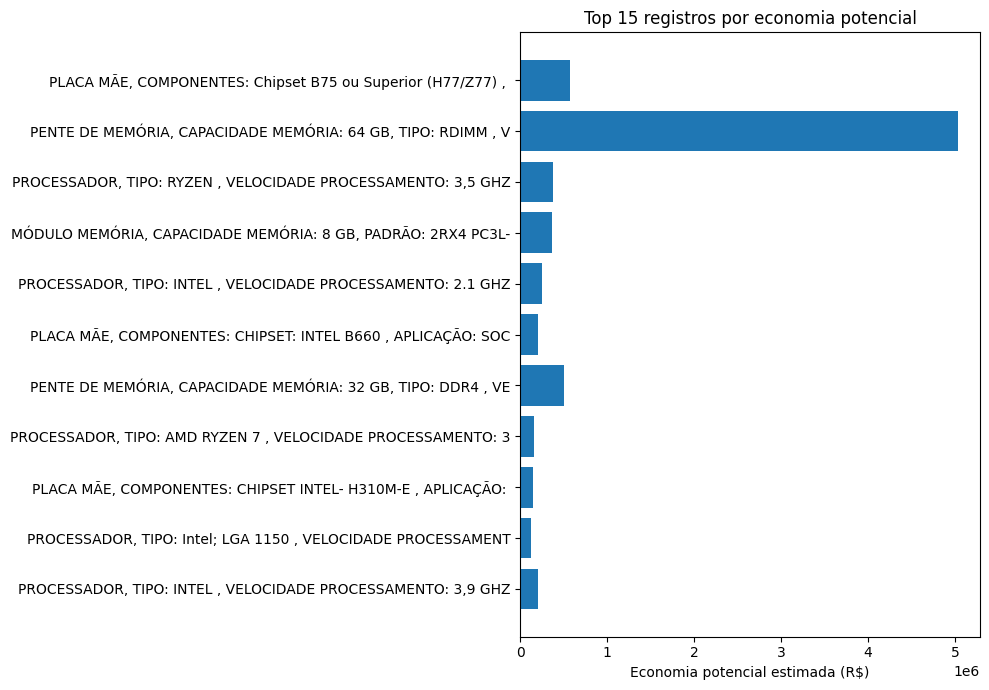

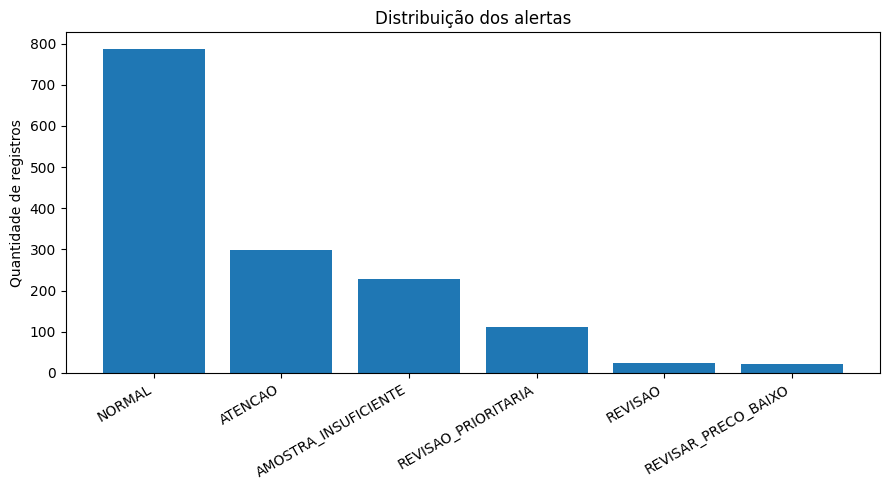

In [ ]:
# 18) Gráficos para revisão
# Gráfico 1: maiores economias potenciais
# Verifica a condição antes de executar o bloco abaixo.
if not gold.empty and 'economia_potencial' in gold.columns:
    # Armazena em `top` o valor ou resultado calculado nesta etapa.
    top = gold.nlargest(15, 'economia_potencial').copy()
    # Verifica a condição antes de executar o bloco abaixo.
    if not top.empty:
        # Armazena em `labels` o valor ou resultado calculado nesta etapa.
        labels = top.get('descricaoItem', top['codigoItemCatalogo'].astype(str)).astype(str).str.slice(0, 60)
        # Executa `plt.figure` para realizar a operação indicada.
        plt.figure(figsize=(10, 7))
        # Executa `plt.barh` para realizar a operação indicada.
        plt.barh(labels[::-1], top['economia_potencial'][::-1])
        # Executa `plt.xlabel` para realizar a operação indicada.
        plt.xlabel('Economia potencial estimada (R$)')
        # Executa `plt.title` para realizar a operação indicada.
        plt.title('Top 15 registros por economia potencial')
        # Executa `plt.tight_layout` para realizar a operação indicada.
        plt.tight_layout()
        # Armazena em `graf1` o valor ou resultado calculado nesta etapa.
        graf1 = RELATORIOS / 'top_economia_potencial.png'
        # Executa `plt.savefig` para realizar a operação indicada.
        plt.savefig(graf1, dpi=150, bbox_inches='tight')
        # Executa `plt.show` para realizar a operação indicada.
        plt.show()

# Gráfico 2: distribuição dos alertas
# Verifica a condição antes de executar o bloco abaixo.
if 'alerta' in gold.columns:
    # Armazena em `cont` o valor ou resultado calculado nesta etapa.
    cont = gold['alerta'].value_counts()
    # Executa `plt.figure` para realizar a operação indicada.
    plt.figure(figsize=(9, 5))
    # Executa `plt.bar` para realizar a operação indicada.
    plt.bar(cont.index.astype(str), cont.values)
    # Executa `plt.ylabel` para realizar a operação indicada.
    plt.ylabel('Quantidade de registros')
    # Executa `plt.title` para realizar a operação indicada.
    plt.title('Distribuição dos alertas')
    # Executa `plt.xticks` para realizar a operação indicada.
    plt.xticks(rotation=30, ha='right')
    # Executa `plt.tight_layout` para realizar a operação indicada.
    plt.tight_layout()
    # Armazena em `graf2` o valor ou resultado calculado nesta etapa.
    graf2 = RELATORIOS / 'distribuicao_alertas.png'
    # Executa `plt.savefig` para realizar a operação indicada.
    plt.savefig(graf2, dpi=150, bbox_inches='tight')
    # Executa `plt.show` para realizar a operação indicada.
    plt.show()

In [ ]:

# 19) INTERFACE INTERATIVA COMPRA CLARA — TEMA ESCURO

# Importa bibliotecas necessárias para esta etapa.
import ipywidgets as widgets
# Importa recursos específicos de um módulo.
from IPython.display import display, HTML, clear_output
# Importa recursos específicos de um módulo.
from IPython.display import Markdown
# Importa bibliotecas necessárias para esta etapa.
import matplotlib.pyplot as plt
# Importa bibliotecas necessárias para esta etapa.
import pandas as pd
# Importa bibliotecas necessárias para esta etapa.
import numpy as np
# Importa bibliotecas necessárias para esta etapa.
import re
# Importa bibliotecas necessárias para esta etapa.
import html
# Importa recursos específicos de um módulo.
from IPython.display import FileLink

# ---------------------------------------------------------
# 1. VERIFICAÇÃO DOS DADOS
# ---------------------------------------------------------

# Verifica a condição antes de executar o bloco abaixo.
if 'gold' not in globals() or gold.empty:
    # Interrompe a execução sinalizando uma condição de erro.
    raise RuntimeError(
        "A camada Gold não está disponível. "
        "Execute primeiro as células do pipeline."
    )

# Armazena em `df_base` o valor ou resultado calculado nesta etapa.
df_base = gold.copy()

# ---------------------------------------------------------
# 2. ESTILO VISUAL ESCURO
# ---------------------------------------------------------

# Executa `display` para realizar a operação indicada.
display(HTML("""
<style>
.cc-root {
    background: #101722;
    color: #E8EEF5;
    padding: 22px;
    border-radius: 15px;
    font-family: Arial, sans-serif;
}
.cc-title {
    color: #F5F7FA;
    font-size: 27px;
    font-weight: 700;
}
.cc-subtitle {
    color: #9EADBF;
    margin-top: 5px;
    margin-bottom: 20px;
}
.cc-card {
    background: #1B2838;
    border: 1px solid #2B3B50;
    border-radius: 12px;
    padding: 17px;
    min-width: 145px;
}
.cc-label {
    color: #A9B8CA;
    font-size: 12px;
}
.cc-value {
    color: #F4F7FA;
    font-size: 25px;
    font-weight: bold;
    margin-top: 8px;
}
.cc-green { color: #55D6A5; }
.cc-yellow { color: #FBBF24; }
.cc-blue { color: #60A5FA; }
.cc-purple { color: #C4A7FF; }
.cc-section {
    color: #F4F7FA;
    font-size: 18px;
    font-weight: bold;
    margin: 15px 0 8px 0;
}
.cc-note {
    background: #192B38;
    border-left: 4px solid #55D6A5;
    padding: 12px;
    border-radius: 7px;
    color: #C6D3E1;
}
.widget-label {
    color: #DCE5EF !important;
}
.jp-OutputArea-output {
    background: #101722 !important;
}
</style>
"""))

# ---------------------------------------------------------
# 3. FUNÇÕES AUXILIARES
# ---------------------------------------------------------

# Define a função `moeda`, responsável por moeda.
def moeda(valor):
    # Executa o trecho protegido e permite tratar possíveis exceções.
    try:
        # Devolve o resultado calculado pela função.
        return (
            "R$ "
            + f"{float(valor):,.2f}"
            .replace(",", "X")
            .replace(".", ",")
            .replace("X", ".")
        )
    except Exception:
        # Devolve o resultado calculado pela função.
        return "R$ 0,00"


# Define a função `filtrar_dados`, responsável por filtrar dados.
def filtrar_dados():
    # Armazena em `df` o valor ou resultado calculado nesta etapa.
    df = df_base.copy()

    # Armazena em `termo` o valor ou resultado calculado nesta etapa.
    termo = campo_busca.value.strip()

    # Verifica a condição antes de executar o bloco abaixo.
    if termo:
        # Armazena em `termo_norm` o valor ou resultado calculado nesta etapa.
        termo_norm = normalizar_texto(termo)

        # Armazena em `descricao` o valor ou resultado calculado nesta etapa.
        descricao = (
            df.get(
                'descricaoItem',
                pd.Series('', index=df.index)
            )
            .fillna('')
            .map(normalizar_texto)
        )

        # Armazena em `codigo` o valor ou resultado calculado nesta etapa.
        codigo = (
            df.get(
                'codigoItemCatalogo',
                pd.Series('', index=df.index)
            )
            .astype(str)
        )

        # Armazena em `mascara` o valor ou resultado calculado nesta etapa.
        mascara = (
            descricao.str.contains(
                re.escape(termo_norm),
                regex=True,
                na=False
            )
            |
            codigo.str.contains(
                re.escape(termo),
                regex=True,
                na=False
            )
        )

        # Armazena em `df` o valor ou resultado calculado nesta etapa.
        df = df[mascara]

    # Verifica a condição antes de executar o bloco abaixo.
    if filtro_alerta.value != "TODOS":
        # Armazena em `df` o valor ou resultado calculado nesta etapa.
        df = df[
            df['alerta'].astype(str)
            == filtro_alerta.value
        ]

    # Verifica a condição antes de executar o bloco abaixo.
    if filtro_uf.value != "TODOS":
        # Verifica a condição antes de executar o bloco abaixo.
        if 'estado' in df.columns:
            # Armazena em `df` o valor ou resultado calculado nesta etapa.
            df = df[
                df['estado'].astype(str).str.upper()
                == filtro_uf.value
            ]

    # Verifica a condição antes de executar o bloco abaixo.
    if somente_alertas.value:
        # Armazena em `df` o valor ou resultado calculado nesta etapa.
        df = df[
            df['alerta'].astype(str) != 'NORMAL'
        ]

    # Verifica a condição antes de executar o bloco abaixo.
    if 'economia_potencial' in df.columns:
        # Armazena em `df` o valor ou resultado calculado nesta etapa.
        df = df.sort_values(
            'economia_potencial',
            ascending=False
        )

    # Devolve o resultado calculado pela função.
    return df


# ---------------------------------------------------------
# 4. COMPONENTES DOS FILTROS
# ---------------------------------------------------------

# Armazena em `estilo` o valor ou resultado calculado nesta etapa.
estilo = {'description_width': 'initial'}

# Armazena em `campo_busca` o valor ou resultado calculado nesta etapa.
campo_busca = widgets.Text(
    placeholder='Ex.: processador, memória RAM, placa-mãe...',
    description='Pesquisar:',
    layout=widgets.Layout(width='100%'),
    style=estilo
)

# Armazena em `alertas_disponiveis` o valor ou resultado calculado nesta etapa.
alertas_disponiveis = (
    ['TODOS']
    + sorted(
        df_base['alerta']
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )
)

# Armazena em `filtro_alerta` o valor ou resultado calculado nesta etapa.
filtro_alerta = widgets.Dropdown(
    options=alertas_disponiveis,
    value='TODOS',
    description='Classificação:',
    layout=widgets.Layout(width='100%'),
    style=estilo
)

# Armazena em `ufs` o valor ou resultado calculado nesta etapa.
ufs = ['TODOS']

# Verifica a condição antes de executar o bloco abaixo.
if 'estado' in df_base.columns:
    # Armazena em `ufs` o valor ou resultado calculado nesta etapa.
    ufs += sorted(
        df_base['estado']
        .dropna()
        .astype(str)
        .str.upper()
        .unique()
        .tolist()
    )

# Armazena em `filtro_uf` o valor ou resultado calculado nesta etapa.
filtro_uf = widgets.Dropdown(
    options=ufs,
    value='TODOS',
    description='Estado:',
    layout=widgets.Layout(width='100%'),
    style=estilo
)

# Armazena em `somente_alertas` o valor ou resultado calculado nesta etapa.
somente_alertas = widgets.Checkbox(
    value=False,
    description='Mostrar somente registros com alertas',
    indent=False,
    style=estilo
)

# Armazena em `botao_filtrar` o valor ou resultado calculado nesta etapa.
botao_filtrar = widgets.Button(
    description='Aplicar filtros',
    icon='search',
    button_style='success',
    layout=widgets.Layout(width='180px', height='40px')
)

# Armazena em `botao_limpar` o valor ou resultado calculado nesta etapa.
botao_limpar = widgets.Button(
    description='Limpar filtros',
    icon='refresh',
    layout=widgets.Layout(width='150px', height='40px')
)

# ---------------------------------------------------------
# 5. ÁREAS DE CONTEÚDO
# ---------------------------------------------------------

# Armazena em `saida_dashboard` o valor ou resultado calculado nesta etapa.
saida_dashboard = widgets.Output()
# Armazena em `saida_pesquisa` o valor ou resultado calculado nesta etapa.
saida_pesquisa = widgets.Output()
# Armazena em `saida_alertas` o valor ou resultado calculado nesta etapa.
saida_alertas = widgets.Output()
# Armazena em `saida_metodologia` o valor ou resultado calculado nesta etapa.
saida_metodologia = widgets.Output()

# ---------------------------------------------------------
# 6. DASHBOARD
# ---------------------------------------------------------

# Define a função `atualizar_dashboard`, responsável por atualizar dashboard.
def atualizar_dashboard(df):

    # Abre um contexto de execução e garante seu encerramento adequado.
    with saida_dashboard:
        # Executa `clear_output` para realizar a operação indicada.
        clear_output(wait=True)

        # Armazena em `total` o valor ou resultado calculado nesta etapa.
        total = len(df)

        # Armazena em `total_alertas` o valor ou resultado calculado nesta etapa.
        total_alertas = (
            df['alerta']
            .isin(['REVISAO', 'REVISAO_PRIORITARIA'])
            .sum()
            if 'alerta' in df else 0
        )

        # Armazena em `total_catmat` o valor ou resultado calculado nesta etapa.
        total_catmat = (
            df['codigoItemCatalogo'].nunique()
            if 'codigoItemCatalogo' in df else 0
        )

        # Armazena em `economia` o valor ou resultado calculado nesta etapa.
        economia = (
            df['economia_potencial'].sum()
            if 'economia_potencial' in df else 0
        )

        # Armazena em `preco_mediano` o valor ou resultado calculado nesta etapa.
        preco_mediano = (
            df['precoUnitario'].median()
            if 'precoUnitario' in df else 0
        )

        # Executa `display` para realizar a operação indicada.
        display(HTML(f"""
        <div class="cc-root">
            <div class="cc-title">Visão geral</div>
            <div class="cc-subtitle">
                Indicadores calculados com os dados filtrados
                da camada Gold.
            </div>
            <div style="display:grid;
                        grid-template-columns:repeat(auto-fit,minmax(160px,1fr));
                        gap:12px;">
                <div class="cc-card">
                    <div class="cc-label">REGISTROS ANALISADOS</div>
                    <div class="cc-value cc-blue">{total:,}</div>
                </div>
                <div class="cc-card">
                    <div class="cc-label">ALERTAS DE REVISÃO</div>
                    <div class="cc-value cc-yellow">{total_alertas:,}</div>
                </div>
                <div class="cc-card">
                    <div class="cc-label">ITENS CATMAT</div>
                    <div class="cc-value cc-purple">{total_catmat:,}</div>
                </div>
                <div class="cc-card">
                    <div class="cc-label">ECONOMIA POTENCIAL</div>
                    <div class="cc-value cc-green">{moeda(economia)}</div>
                </div>
            </div>
            <br>
            <div class="cc-note">
                A economia potencial é uma estimativa estatística,
                não uma economia efetivamente realizada.
            </div>
        </div>
        """))

        # Verifica a condição antes de executar o bloco abaixo.
        if df.empty:
            # Executa `print` para realizar a operação indicada.
            print("Nenhum registro encontrado para os filtros.")
            # Devolve o resultado calculado pela função.
            return

        # Gráficos
        # Armazena em `(fig, axes)` o valor ou resultado calculado nesta etapa.
        fig, axes = plt.subplots(
            1, 2, figsize=(15, 5)
        )

        # Executa `fig.patch.set_facecolor` para realizar a operação indicada.
        fig.patch.set_facecolor('#101722')

        # Percorre os elementos da coleção, executando o bloco para cada um.
        for ax in axes:
            # Executa `ax.set_facecolor` para realizar a operação indicada.
            ax.set_facecolor('#1B2838')
            # Executa `ax.tick_params` para realizar a operação indicada.
            ax.tick_params(colors='#DCE5EF')
            # Executa `ax.xaxis.label.set_color` para realizar a operação indicada.
            ax.xaxis.label.set_color('#DCE5EF')
            # Executa `ax.yaxis.label.set_color` para realizar a operação indicada.
            ax.yaxis.label.set_color('#DCE5EF')
            # Executa `ax.title.set_color` para realizar a operação indicada.
            ax.title.set_color('#F4F7FA')

        # Verifica a condição antes de executar o bloco abaixo.
        if 'alerta' in df.columns:
            # Armazena em `contagem` o valor ou resultado calculado nesta etapa.
            contagem = df['alerta'].value_counts()

            # Executa `axes[0].bar` para realizar a operação indicada.
            axes[0].bar(
                contagem.index.astype(str),
                contagem.values
            )

            # Executa `axes[0].set_title` para realizar a operação indicada.
            axes[0].set_title('Distribuição dos alertas')
            # Executa `axes[0].tick_params` para realizar a operação indicada.
            axes[0].tick_params(axis='x', rotation=35)

        # Verifica a condição antes de executar o bloco abaixo.
        if (
            'economia_potencial' in df.columns
            and 'descricaoItem' in df.columns
        ):
            # Armazena em `top` o valor ou resultado calculado nesta etapa.
            top = df.nlargest(10, 'economia_potencial')

            # Armazena em `top` o valor ou resultado calculado nesta etapa.
            top = top.sort_values(
                'economia_potencial',
                ascending=True
            )

            # NOVO: cria etiquetas numeradas para identificar cada item no gráfico.
            # O enumerate() fornece a posição de cada descrição na lista.
            # O i + 1 faz a numeração começar em 1, em vez de 0.
            # desc[:35] limita o texto a 35 caracteres para caber melhor no gráfico.
            labels = [
                f"{i + 1}. {desc[:35]}"
                for i, desc in enumerate(
                    top['descricaoItem'].astype(str)
                )
            ]

            # NOVO: usa as etiquetas numeradas no eixo vertical do gráfico.
            # Os valores de economia continuam sendo os mesmos, associados
            # às descrições correspondentes na mesma ordem.
            # Executa `axes[1].barh` para desenhar as barras horizontais.
            axes[1].barh(
                labels,
                top['economia_potencial']
            )

            # Executa `axes[1].set_title` para realizar a operação indicada.
            axes[1].set_title('Maiores economias potenciais')
            # Executa `axes[1].set_xlabel` para realizar a operação indicada.
            axes[1].set_xlabel('Valor estimado (R$)')

        # Executa `plt.tight_layout` para realizar a operação indicada.
        plt.tight_layout()
        # Executa `plt.show` para realizar a operação indicada.
        plt.show()

        # Executa `display` para realizar a operação indicada.
        display(HTML(
            f'<div class="cc-section">Preço mediano observado: '
            f'{moeda(preco_mediano)}</div>'
        ))


# ---------------------------------------------------------
# 7. PESQUISA DE ITENS
# ---------------------------------------------------------

# Define a função `atualizar_pesquisa`, responsável por atualizar pesquisa.
def atualizar_pesquisa(df):

    # Abre um contexto de execução e garante seu encerramento adequado.
    with saida_pesquisa:
        # Executa `clear_output` para realizar a operação indicada.
        clear_output(wait=True)

        # Executa `display` para realizar a operação indicada.
        display(HTML(
            '<div class="cc-section">Resultados da pesquisa</div>'
        ))

        # Verifica a condição antes de executar o bloco abaixo.
        if df.empty:
            # Executa `print` para realizar a operação indicada.
            print("Nenhum item encontrado.")
            # Devolve o resultado calculado pela função.
            return

        # Armazena em `colunas` o valor ou resultado calculado nesta etapa.
        colunas = [
            'codigoItemCatalogo',
            'descricaoItem',
            'estado',
            'precoUnitario',
            'benchmark_mediana',
            'desvio_percentual',
            'alerta',
            'confianca'
        ]

        # Armazena em `colunas` o valor ou resultado calculado nesta etapa.
        colunas = [
            c for c in colunas if c in df.columns
        ]

        # Executa `display` para realizar a operação indicada.
        display(
            df[colunas].head(200)
            .reset_index(drop=True)
            .style.format({
                'precoUnitario': moeda,
                'benchmark_mediana': moeda,
                'desvio_percentual': '{:.2f}%'
            }, na_rep='—')
        )

        # Executa `print` para realizar a operação indicada.
        print(f"Total de registros encontrados: {len(df)}")


# ---------------------------------------------------------
# 8. CENTRAL DE ALERTAS
# ---------------------------------------------------------

# Define a função `atualizar_alertas`, responsável por atualizar alertas.
def atualizar_alertas(df):

    # Abre um contexto de execução e garante seu encerramento adequado.
    with saida_alertas:
        # Executa `clear_output` para realizar a operação indicada.
        clear_output(wait=True)

        # Executa `display` para realizar a operação indicada.
        display(HTML(
            '<div class="cc-section">Central de alertas</div>'
        ))

        # Verifica a condição antes de executar o bloco abaixo.
        if 'alerta' not in df.columns:
            # Executa `print` para realizar a operação indicada.
            print("Coluna de alertas não encontrada.")
            # Devolve o resultado calculado pela função.
            return

        # Armazena em `alertas` o valor ou resultado calculado nesta etapa.
        alertas = df[
            df['alerta'].isin([
                'REVISAO_PRIORITARIA',
                'REVISAO',
                'ATENCAO',
                'REVISAR_PRECO_BAIXO'
            ])
        ].copy()

        # Verifica a condição antes de executar o bloco abaixo.
        if alertas.empty:
            # Executa `print` para realizar a operação indicada.
            print("Nenhum alerta encontrado.")
            # Devolve o resultado calculado pela função.
            return

        # Verifica a condição antes de executar o bloco abaixo.
        if 'economia_potencial' in alertas:
            # Armazena em `alertas` o valor ou resultado calculado nesta etapa.
            alertas = alertas.sort_values(
                'economia_potencial',
                ascending=False
            )

        # Armazena em `colunas` o valor ou resultado calculado nesta etapa.
        colunas = [
            'descricaoItem',
            'codigoItemCatalogo',
            'precoUnitario',
            'benchmark_mediana',
            'desvio_percentual',
            'economia_potencial',
            'confianca',
            'alerta',
            'justificativa_alerta'
        ]

        # Armazena em `colunas` o valor ou resultado calculado nesta etapa.
        colunas = [
            c for c in colunas if c in alertas.columns
        ]

        # Executa `display` para realizar a operação indicada.
        display(
            alertas[colunas].head(200)
            .reset_index(drop=True)
            .style.format({
                'precoUnitario': moeda,
                'benchmark_mediana': moeda,
                'economia_potencial': moeda,
                'desvio_percentual': '{:.2f}%'
            }, na_rep='—')
        )

        # Executa `print` para realizar a operação indicada.
        print(
            f"Registros que precisam de atenção: {len(alertas)}"
        )


# ---------------------------------------------------------
# 9. METODOLOGIA
# ---------------------------------------------------------

# Abre um contexto de execução e garante seu encerramento adequado.
with saida_metodologia:
    # Executa `display` para realizar a operação indicada.
    display(HTML("""
    <div class="cc-root">
        <div class="cc-title">Metodologia do Compra Clara</div>

        <div class="cc-section">1. Origem dos dados</div>
        Dados públicos consultados na API oficial do
        Compras.gov.br, com informações de catálogo CATMAT
        e pesquisa de preços.

        <div class="cc-section">2. Data Lake</div>
        <b>Bronze:</b> preservação dos dados brutos.<br>
        <b>Silver:</b> limpeza, padronização e deduplicação.<br>
        <b>Gold:</b> benchmarks, indicadores e classificação.

        <div class="cc-section">3. Comparação de preços</div>
        O sistema utiliza benchmark leave-one-out,
        preferindo referências por UF e recorrendo ao
        benchmark nacional quando a amostra regional
        é insuficiente.

        <div class="cc-section">4. Detecção de anomalias</div>
        São utilizados os métodos IQR e MAD
        (robust z-score) para identificar preços
        estatisticamente fora do padrão.

        <div class="cc-section">5. Revisão humana</div>
        Os alertas indicam registros que merecem
        investigação. Um outlier não comprova fraude
        ou irregularidade.

        <div class="cc-note">
            O Compra Clara é uma ferramenta de triagem
            e transparência, não um sistema de decisão
            automática sobre legalidade de compras.
        </div>
    </div>
    """))

# ---------------------------------------------------------
# 10. ATUALIZAÇÃO GERAL
# ---------------------------------------------------------

# Define a função `atualizar_interface`, responsável por atualizar interface.
def atualizar_interface(_=None):

    # Armazena em `df` o valor ou resultado calculado nesta etapa.
    df = filtrar_dados()

    # Executa `atualizar_dashboard` para realizar a operação indicada.
    atualizar_dashboard(df)
    # Executa `atualizar_pesquisa` para realizar a operação indicada.
    atualizar_pesquisa(df)
    # Executa `atualizar_alertas` para realizar a operação indicada.
    atualizar_alertas(df)


# Define a função `limpar_filtros`, responsável por limpar filtros.
def limpar_filtros(_=None):

    # Armazena em `campo_busca.value` o valor ou resultado calculado nesta etapa.
    campo_busca.value = ''
    # Armazena em `filtro_alerta.value` o valor ou resultado calculado nesta etapa.
    filtro_alerta.value = 'TODOS'
    # Armazena em `filtro_uf.value` o valor ou resultado calculado nesta etapa.
    filtro_uf.value = 'TODOS'
    # Armazena em `somente_alertas.value` o valor ou resultado calculado nesta etapa.
    somente_alertas.value = False

    # Executa `atualizar_interface` para realizar a operação indicada.
    atualizar_interface()


# Executa `botao_filtrar.on_click` para realizar a operação indicada.
botao_filtrar.on_click(atualizar_interface)
# Executa `botao_limpar.on_click` para realizar a operação indicada.
botao_limpar.on_click(limpar_filtros)

# ---------------------------------------------------------
# 11. ABAS DA INTERFACE
# ---------------------------------------------------------

# Armazena em `abas` o valor ou resultado calculado nesta etapa.
abas = widgets.Tab(
    children=[
        saida_dashboard,
        saida_pesquisa,
        saida_alertas,
        saida_metodologia
    ],
    layout=widgets.Layout(width='100%')
)

# Executa `abas.set_title` para realizar a operação indicada.
abas.set_title(0, 'Dashboard')
# Executa `abas.set_title` para realizar a operação indicada.
abas.set_title(1, 'Pesquisar itens')
# Executa `abas.set_title` para realizar a operação indicada.
abas.set_title(2, 'Alertas')
# Executa `abas.set_title` para realizar a operação indicada.
abas.set_title(3, 'Metodologia')

# ---------------------------------------------------------
# 12. EXIBIÇÃO FINAL
# ---------------------------------------------------------

# Armazena em `cabecalho` o valor ou resultado calculado nesta etapa.
cabecalho = widgets.HTML("""
<div style="
    background:#101722;
    color:#F4F7FA;
    padding:20px;
    border-radius:14px;
    border-bottom:3px solid #55D6A5;
">
    <div style="font-size:28px;font-weight:bold;">
        COMPRA CLARA
    </div>
    <div style="color:#A9B8CA;font-size:14px;">
        Inteligência e transparência nos preços públicos
    </div>
</div>
""")

# Armazena em `painel_filtros` o valor ou resultado calculado nesta etapa.
painel_filtros = widgets.VBox([
    widgets.HTML(
        '<div style="color:#F4F7FA;font-weight:bold;'
        'font-size:17px;margin-top:12px;">Filtros de análise</div>'
    ),
    campo_busca,
    widgets.HBox([
        filtro_alerta,
        filtro_uf
    ]),
    somente_alertas,
    widgets.HBox([
        botao_filtrar,
        botao_limpar
    ])
])

# Executa `display` para realizar a operação indicada.
display(widgets.VBox([
    cabecalho,
    painel_filtros,
    abas
]))

# Carrega os dados iniciais
# Executa `atualizar_interface` para realizar a operação indicada.
atualizar_interface()

# Executa `print` para realizar a operação indicada.
print("Interface Compra Clara carregada com sucesso.")

Interface Compra Clara carregada com sucesso.


Etapa G — PySpark (demonstração Big Data)
O pipeline operacional acima usa Pandas porque o MVP pode ter volume moderado. Para atender ao componente acadêmico de Big Data, este bloco lê a Silver em Spark e reproduz um benchmark distribuído com mediana aproximada (percentile_approx).

In [ ]:
# 20) Benchmark equivalente em PySpark
# Importa recursos específicos de um módulo.
from pyspark.sql import SparkSession, functions as F

# Armazena em `spark` o valor ou resultado calculado nesta etapa.
spark = (
    SparkSession.builder
    .appName('CompraClara')
    .getOrCreate()
)

# Armazena em `silver_parquet` o valor ou resultado calculado nesta etapa.
silver_parquet = str(SILVER / 'precos_silver_latest.parquet')
# Armazena em `spark_silver` o valor ou resultado calculado nesta etapa.
spark_silver = spark.read.parquet(silver_parquet)

# Armazena em `spark_gold_benchmark` o valor ou resultado calculado nesta etapa.
spark_gold_benchmark = (
    spark_silver
    .groupBy('grupo_comparavel', 'regiao_uf')
    .agg(
        F.count('*').alias('n'),
        F.avg('precoUnitario').alias('media'),
        F.expr('percentile_approx(precoUnitario, 0.5, 10000)').alias('mediana'),
        F.expr('percentile_approx(precoUnitario, 0.25, 10000)').alias('q1'),
        F.expr('percentile_approx(precoUnitario, 0.75, 10000)').alias('q3'),
        F.min('precoUnitario').alias('min'),
        F.max('precoUnitario').alias('max'),
    )
    .withColumn('iqr', F.col('q3') - F.col('q1'))
)

# Executa `spark_gold_benchmark.show` para realizar a operação indicada.
spark_gold_benchmark.show(20, truncate=False)

+-------------------------+---------+---+------------------+-------+-------+-------+-------+-------+------------------+
|grupo_comparavel         |regiao_uf|n  |media             |mediana|q1     |q3     |min    |max    |iqr               |
+-------------------------+---------+---+------------------+-------+-------+-------+-------+-------+------------------+
|11274|UF=NA|UM=NA|CAP=0.0|CE       |8  |156.75            |130.0  |99.0   |199.0  |99.0   |199.0  |100.0             |
|11274|UF=NA|UM=NA|CAP=0.0|MA       |1  |425.0             |425.0  |425.0  |425.0  |425.0  |425.0  |0.0               |
|11274|UF=NA|UM=NA|CAP=0.0|MG       |2  |479.795           |248.09 |248.09 |711.5  |248.09 |711.5  |463.40999999999997|
|11274|UF=NA|UM=NA|CAP=0.0|PA       |57 |2198.7796877192986|1433.66|601.07 |3999.0 |48.96  |6825.0 |3397.93           |
|11274|UF=NA|UM=NA|CAP=0.0|PR       |1  |275.0             |275.0  |275.0  |275.0  |275.0  |275.0  |0.0               |
|11274|UF=NA|UM=NA|CAP=0.0|RJ       |5  

Resultado esperado do Compra Clara
A tabela Gold é a saída principal para decisão. Ela permite responder:
- Qual foi o preço observado?
- Qual é o benchmark comparável?
- Quantas observações sustentam esse benchmark?
- O valor está fora do padrão robusto?
- Qual a diferença percentual?
- Qual a economia potencial estimada?
- Qual a confiança do alerta?
- Qual registro deve ser priorizado para revisão humana?
Observação metodológica
Um outlier não prova irregularidade ou fraude. Diferenças de especificação, unidade, marca, localização, modalidade, quantidade, urgência ou contexto da contratação podem explicar valores distintos. O Compra Clara funciona como triagem analítica, não como decisão automática.